# 5G SA Video Call Evaluation: Metrics, QoE and Plots

This notebook processes the measurements of the 18 experimental scenarios and produces the tables and figures used to compare **srsRAN** and **OAI** under three network conditions. It is the analysis companion of the methodology described in this repository.

## What it does

1. Reads the per-scenario CSV files (audio and video, both directions).
2. Computes the speech, video and multimedia quality scores ($S_q$, $V_q$, $MM_q$) of ITU-T G.1070 for each of the 21 iterations.
3. Summarizes each scenario as mean ± SEM (standard error of the mean, $s/\sqrt{21}$) and prints LaTeX tables.
4. Groups scenarios into three conditions per platform and propagates the uncertainty.
5. Draws the comparison charts and the boxplots.

## Scenarios and conditions

| Condition | Description | srsRAN | OAI |
|---|---|---|---|
| 1 | No congestion, 5QI 9 | scenes 1-3 | scenes 10-12 |
| 2 | Congestion, 5QI 9 | scenes 4-6 | scenes 13-15 |
| 3 | Congestion, 5QI 1 | scenes 7-9 | scenes 16-18 |

Each condition averages three scenarios because media encryption operates at the application layer.

## Input files

Place these files in the same folder as the notebook (`N` = scene number 1-18):

- `audio_AB_sceneN.csv`, `audio_BA_sceneN.csv`
- `video_AB_sceneN.csv`, `video_BA_sceneN.csv`

They are semicolon-separated and each has one row per iteration (21 rows). The columns used are `packet_loss_%`, `bitrate_kbps`, `delay_network_ms` and `jitter_network_ms`.

## Output files

- `resultados_escenario_N.json`: mean and standard error of every metric for scene `N`.
- `cond_results.json`: values grouped by condition, used by the charts.
- `graficos_overlap/` and `graficos_boxplot/`: PDF charts and a ZIP with all of them.

## How to run

Run the cells **from top to bottom**. The cells in sections 1 to 3 only define functions and constants. The first cell that does work is `main()` in section 4, and the charts in sections 6 and 7 need the files that it generates.

## Contents

1. Quality models and data reading
2. Comparison and plotting functions
3. G.1070 constants
4. Main pipeline
5. Per-scenario charts (optional)
6. Summary charts by condition
7. Boxplots

## 1. Quality models and data reading

This cell defines:

- **`SpeechQuality`, `VideoQuality`, `MMQuality`**: implementation of the ITU-T G.1070 model. They take the packet loss, bitrate, delay and jitter of a flow and return $S_q$, $V_q$ and $MM_q$. The delay used by the models is $T \approx d + j$ (network delay plus jitter), a lower bound of the real delay, so the resulting scores are an upper bound of the real quality.
- **`read_csv` and `read_all_scenes`**: load the CSV files. `read_all_scenes` is the one used by `main()` and reads every scene and direction with `;` as delimiter.
- **`create_results_table` and `create_qoe_table`**: print the network and QoE tables of a scene in LaTeX.
- **`save_results`**: stores the results of a scene in `resultados_escenario_N.json`.

In [ ]:
import numpy as np
import pandas as pd
import os
import statistics
import json

class SpeechQuality:
    def __init__(self, constants, packet_loss, bitrate, ts, jitter):
        self.telr = constants["TELR"]
        self.table = constants["TABLE"]
        self.packet_loss = packet_loss/100
        self.bitrate = bitrate
        self.ts = ts + jitter
        self.kvalue = (0.08 * self.ts + 10) if self.ts < 100 else 18

    def _get_bpls(self):

        table_bpls = [
            (23.85, 4.9),
            (23.05, 4.6),
            (15.85, 4.6),
            (12.65, 4.3),
            (8.85,  4.3),
            (6.6,   4.3)
        ]

        closest_bitrate = min(
            table_bpls,
            key=lambda x: abs(x[0] - self.bitrate)
        )

        self.bpls = closest_bitrate[1]

    def _get_ieswb(self):

        if self.bitrate >= self.table[0][0]:
            self.ieswb = self.table[0][1]


        if self.bitrate <= self.table[-1][0]:
            self.ieswb = self.table[-1][1]


        closest_bitrate = min(self.table, key=lambda x: abs(x[0] - self.bitrate))
        self.ieswb = closest_bitrate[1]

    def _get_tervwb(self):
        result = (
            self.telr
            + self.kvalue
            + (6 * np.exp(-0.3 * self.ts * self.ts))
            - (40 * (np.log(15) + np.log(10 + self.ts) - np.log(150 + self.ts)))
        )
        self.tervwb = result

    def _get_rewb(self):
        self.rewb = 80 + 3 * (self.tervwb - 14)

    def _get_idtewb(self):
        brack_right = (129 - self.rewb) * 0.5
        brack_left = np.sqrt(((129 - self.rewb) ** 2) * 0.25 + 100) - 1
        res = (1 - np.exp(-self.ts)) * (brack_right + brack_left)
        self.idtewb = res

    def _get_ieffwb(self):
        self.ieffwb = self.ieswb + (95 - self.ieswb) * (
            (self.packet_loss) / (self.packet_loss + self.bpls)
        )

    def _get_qx(self):
        q = 129 - self.idtewb - self.ieffwb
        self.qx = q / 1.29

    def get_value(self):
        # Initiate all values
        self._get_bpls()
        self._get_ieswb()
        self._get_tervwb()
        self._get_rewb()
        self._get_idtewb()
        self._get_ieffwb()
        self._get_qx()

        if self.qx <= 0:
            return 1
        elif self.qx < 100:
            return (
                1
                + (0.035 * self.qx)
                + self.qx * (self.qx - 60) * (100 - self.qx) * (7 / 1000000)
            )
        else:
            return 4.5

class VideoQuality:
    def __init__(self, packet_loss, bitrate, tv, jitter):
        self.frv= 30 # fps
        self.packet_loss = packet_loss/100
        self.bitrate = bitrate*2
        self.tv = tv + jitter


    def _get_Dpplv(self):
      self.Dpplv = v10 + v11 * np.exp(-self.frv/v8) + v12 *np.exp(-self.bitrate/v9)

    def _get_Drfv(self):
      self.Drfv = v6 + v7 * self.bitrate

    def _get_Iofr(self):

      den = 1 + (self.bitrate/v4)**v5

      self.Iofr = v3 - v3/den

    def _get_Ofr(self):

      self.Ofr = v1 + v2 * self.bitrate

    def _get_Icode(self):

      num = (np.log(self.frv) - np.log(self.Ofr))**2
      den = 2*(self.Drfv)**2

      self.Icode= self.Iofr * np.exp(-num/den)

    def get_value(self):
        # Initiate all values
        self._get_Dpplv()
        self._get_Drfv()
        self._get_Iofr()
        self._get_Ofr()
        self._get_Icode()


        return 1 + self.Icode * np.exp(-self.packet_loss/self.Dpplv)

class MMQuality:
    def __init__(self, Ts, Tv, S, V, jitter_s, jitter_v):
        self.ts= Ts + jitter_s
        self.tv = Tv + jitter_v
        self.speech = S
        self.video = V

    def _get_MMsv(self):
      self.MMsv = m5*self.speech+m6*self.video+m7*self.speech*self.video+m8

    def _get_MS(self):

      if self.ts >= self.tv:
        self.MS = min(m11*(self.ts-self.tv)+m12, 0)
      else:
        self.MS = min(m13*(self.tv-self.ts)+m14, 0)

    def _get_MMt(self):

        AD = m9*(self.ts+self.tv) + m10

        self.MMt = max(AD+self.MS,1)

    def get_value(self):
        self._get_MMsv()
        self._get_MS()
        self._get_MMt()

        return m1*self.MMsv + m2*self.MMt + m3*self.MMsv*self.MMt + m4

def read_csv(scene_num, direction):
    """
    Reads the audio and video CSV files for a specific scenario.

    Args:
        scene_num: Scenario number (1-18)
        direction: Flow direction ('AB' or 'BA')

    Returns:
        tuple: (df_audio, df_video) containing the corresponding DataFrames
    """

    audio_file = f"audio_{direction}_scene{scene_num}.csv"
    video_file = f"video_{direction}_scene{scene_num}.csv"

    if not os.path.exists(audio_file):
        raise FileNotFoundError(f"Did not find the file: {audio_file}")
    if not os.path.exists(video_file):
        raise FileNotFoundError(f"Did not find the file: {video_file}")

    df_audio = pd.read_csv(audio_file)
    df_video = pd.read_csv(video_file)

    df_audio['scene'] = scene_num
    df_audio['direction'] = direction
    df_audio['type'] = 'audio'

    df_video['scene'] = scene_num
    df_video['direction'] = direction
    df_video['type'] = 'video'

    return df_audio, df_video

def read_all_scenes(scenes_range=range(1, 10), directions=['AB', 'BA']):
    """
    Reads all CSV files using a semicolon as the delimiter.
    """
    all_data = {}

    for scene in scenes_range:
        all_data[scene] = {}
        for direction in directions:
            try:

                df_audio = pd.read_csv(f"audio_{direction}_scene{scene}.csv", delimiter=';')
                df_video = pd.read_csv(f"video_{direction}_scene{scene}.csv", delimiter=';')

                df_audio['scene'] = scene
                df_audio['direction'] = direction
                df_audio['type'] = 'audio'

                df_video['scene'] = scene
                df_video['direction'] = direction
                df_video['type'] = 'video'

                all_data[scene][direction] = {
                    'audio': df_audio,
                    'video': df_video
                }
                print(f"Loaded: scene {scene}, flow {direction}")
            except FileNotFoundError as e:
                print(f"Did not find: audio_{direction}_scene{scene}.csv o video_{direction}_scene{scene}.csv")
                all_data[scene][direction] = None
            except Exception as e:
                print(f"Error in scene {scene}, {direction}: {e}")
                all_data[scene][direction] = None

    return all_data



def create_results_table(scene,
                         packet_loss_speech_AB, jitter_speech_AB, bitrate_speech_AB, delay_speech_AB,
                         packet_loss_speech_BA, jitter_speech_BA, bitrate_speech_BA, delay_speech_BA,
                         packet_loss_video_AB, jitter_video_AB, bitrate_video_AB, delay_video_AB,
                         packet_loss_video_BA, jitter_video_BA, bitrate_video_BA, delay_video_BA):

    df = pd.DataFrame({
        'Flow': ['Audio A → B', 'Audio B → A', 'Video A → B', 'Video B → A'],
        'Packet Loss [%]': [
            f"{packet_loss_speech_AB[0]:.3f} ± {packet_loss_speech_AB[1]:.3f}",
            f"{packet_loss_speech_BA[0]:.3f} ± {packet_loss_speech_BA[1]:.3f}",
            f"{packet_loss_video_AB[0]:.3f} ± {packet_loss_video_AB[1]:.3f}",
            f"{packet_loss_video_BA[0]:.3f} ± {packet_loss_video_BA[1]:.3f}"
        ],
        'Jitter [ms]': [
            f"{jitter_speech_AB[0]:.3f} ± {jitter_speech_AB[1]:.3f}",
            f"{jitter_speech_BA[0]:.3f} ± {jitter_speech_BA[1]:.3f}",
            f"{jitter_video_AB[0]:.3f} ± {jitter_video_AB[1]:.3f}",
            f"{jitter_video_BA[0]:.3f} ± {jitter_video_BA[1]:.3f}"
        ],
        'Bitrate [kb/s]': [
            f"{bitrate_speech_AB[0]:.3f} ± {bitrate_speech_AB[1]:.3f}",
            f"{bitrate_speech_BA[0]:.3f} ± {bitrate_speech_BA[1]:.3f}",
            f"{bitrate_video_AB[0]:.3f} ± {bitrate_video_AB[1]:.3f}",
            f"{bitrate_video_BA[0]:.3f} ± {bitrate_video_BA[1]:.3f}"
        ],
        'Delay [ms]': [
            f"{delay_speech_AB[0]:.3f} ± {delay_speech_AB[1]:.3f}",
            f"{delay_speech_BA[0]:.3f} ± {delay_speech_BA[1]:.3f}",
            f"{delay_video_AB[0]:.3f} ± {delay_video_AB[1]:.3f}",
            f"{delay_video_BA[0]:.3f} ± {delay_video_BA[1]:.3f}"
        ]
    })

    print("")
    print("\\begin{table}[H]")
    print("\\centering")
    print(f"\\caption{{Métricas de red por flujo para Escenario {scene}.}}")
    print(f"\\label{{tab: A_scene_{scene}}}")
    print("\\begin{tabular}{|c|c|c|c|c|}")
    print("\\hline")
    print("Flujo        & Packet Loss [\\%]    & Jitter {[}ms{]}     & Bitrate {[}kb/s{]}   & Delay {[}ms{]}    \\\\ \\hline")

    flows = ['Audio A $\\rightarrow$ B', 'Audio B $\\rightarrow$ A', 'Video A $\\rightarrow$ B', 'Video B $\\rightarrow$ A']
    packet_losses = [
        f"{packet_loss_speech_AB[0]:.3f} $\\pm$ {packet_loss_speech_AB[1]:.3f}",
        f"{packet_loss_speech_BA[0]:.3f} $\\pm$ {packet_loss_speech_BA[1]:.3f}",
        f"{packet_loss_video_AB[0]:.3f} $\\pm$ {packet_loss_video_AB[1]:.3f}",
        f"{packet_loss_video_BA[0]:.3f} $\\pm$ {packet_loss_video_BA[1]:.3f}"
    ]
    jitters = [
        f"{jitter_speech_AB[0]:.3f} $\\pm$ {jitter_speech_AB[1]:.3f}",
        f"{jitter_speech_BA[0]:.3f} $\\pm$ {jitter_speech_BA[1]:.3f}",
        f"{jitter_video_AB[0]:.3f} $\\pm$ {jitter_video_AB[1]:.3f}",
        f"{jitter_video_BA[0]:.3f} $\\pm$ {jitter_video_BA[1]:.3f}"
    ]
    bitrates = [
        f"{bitrate_speech_AB[0]:.3f} $\\pm$ {bitrate_speech_AB[1]:.3f}",
        f"{bitrate_speech_BA[0]:.3f} $\\pm$ {bitrate_speech_BA[1]:.3f}",
        f"{bitrate_video_AB[0]:.3f} $\\pm$ {bitrate_video_AB[1]:.3f}",
        f"{bitrate_video_BA[0]:.3f} $\\pm$ {bitrate_video_BA[1]:.3f}"
    ]
    delays = [
        f"{delay_speech_AB[0]:.3f} $\\pm$ {delay_speech_AB[1]:.3f}",
        f"{delay_speech_BA[0]:.3f} $\\pm$ {delay_speech_BA[1]:.3f}",
        f"{delay_video_AB[0]:.3f} $\\pm$ {delay_video_AB[1]:.3f}",
        f"{delay_video_BA[0]:.3f} $\\pm$ {delay_video_BA[1]:.3f}"
    ]

    for i in range(4):
        print(f"{flows[i]} & {packet_losses[i]} & {jitters[i]} & {bitrates[i]} & {delays[i]} \\\\ \\hline")

    print("\\end{tabular}")
    print("\\end{table}")
    print("")

    return df


def create_qoe_table(scene, sq_AB, vq_AB, mmq_AB, sq_BA, vq_BA, mmq_BA):

    df = pd.DataFrame({
        'Flujo': ['A → B', 'B → A'],
        '$S_q$ [-]': [f"{sq_AB[0]:.3f} ± {sq_AB[1]:.3f}", f"{sq_BA[0]:.3f} ± {sq_BA[1]:.3f}"],
        '$V_q$ [-]': [f"{vq_AB[0]:.3f} ± {vq_AB[1]:.3f}", f"{vq_BA[0]:.3f} ± {vq_BA[1]:.3f}"],
        '$MM_q$ [-]': [f"{mmq_AB[0]:.3f} ± {mmq_AB[1]:.3f}", f"{mmq_BA[0]:.3f} ± {mmq_BA[1]:.3f}"]
    })

    print("")
    print("\\begin{table}[H]")
    print("\\centering")
    print(f"\\caption{{Métricas de QoE por flujo para Escenario {scene}.}}")
    print(f"\\label{{tab: A_mmq_{scene}}}")
    print("\\begin{tabular}{|c|c|c|c|}")
    print("\\hline")
    print("Flujo & $S_q$ [-] & $V_q$ [-] & $MM_q$ [-] \\\\ \\hline")
    print("")


    flows = ['A $\\rightarrow$ B', 'B $\\rightarrow$ A']
    sqs = [
        f"{sq_AB[0]:.3f} $\\pm$ {sq_AB[1]:.3f}",
        f"{sq_BA[0]:.3f} $\\pm$ {sq_BA[1]:.3f}"
    ]
    vqs = [
        f"{vq_AB[0]:.3f} $\\pm$ {vq_AB[1]:.3f}",
        f"{vq_BA[0]:.3f} $\\pm$ {vq_BA[1]:.3f}"
    ]
    mmqs = [
        f"{mmq_AB[0]:.3f} $\\pm$ {mmq_AB[1]:.3f}",
        f"{mmq_BA[0]:.3f} $\\pm$ {mmq_BA[1]:.3f}"
    ]

    for i in range(2):
        print(f"{flows[i]} & {sqs[i]} & {vqs[i]} & {mmqs[i]} \\\\ \\hline")

    print("\\end{tabular}")
    print("\\end{table}")

    return df


def save_results(scene,
                tuple_packet_loss_speech_AB, tuple_jitter_speech_AB, tuple_bitrate_speech_AB, tuple_delay_speech_AB,
                tuple_packet_loss_speech_BA, tuple_jitter_speech_BA, tuple_bitrate_speech_BA, tuple_delay_speech_BA,
                tuple_packet_loss_video_AB, tuple_jitter_video_AB, tuple_bitrate_video_AB, tuple_delay_video_AB,
                tuple_packet_loss_video_BA, tuple_jitter_video_BA, tuple_bitrate_video_BA, tuple_delay_video_BA,
                tuple_sq_AB, tuple_vq_AB, tuple_mmq_AB,
                tuple_sq_BA, tuple_vq_BA, tuple_mmq_BA):
    """
    Save the results of one scene in a JSON file.
    """

    resultados = {
        "escenario": scene,
        "audio_AB": {
            "packet_loss": {"mean": tuple_packet_loss_speech_AB[0], "std": tuple_packet_loss_speech_AB[1]},
            "jitter": {"mean": tuple_jitter_speech_AB[0], "std": tuple_jitter_speech_AB[1]},
            "bitrate": {"mean": tuple_bitrate_speech_AB[0], "std": tuple_bitrate_speech_AB[1]},
            "delay": {"mean": tuple_delay_speech_AB[0], "std": tuple_delay_speech_AB[1]}
        },
        "audio_BA": {
            "packet_loss": {"mean": tuple_packet_loss_speech_BA[0], "std": tuple_packet_loss_speech_BA[1]},
            "jitter": {"mean": tuple_jitter_speech_BA[0], "std": tuple_jitter_speech_BA[1]},
            "bitrate": {"mean": tuple_bitrate_speech_BA[0], "std": tuple_bitrate_speech_BA[1]},
            "delay": {"mean": tuple_delay_speech_BA[0], "std": tuple_delay_speech_BA[1]}
        },
        "video_AB": {
            "packet_loss": {"mean": tuple_packet_loss_video_AB[0], "std": tuple_packet_loss_video_AB[1]},
            "jitter": {"mean": tuple_jitter_video_AB[0], "std": tuple_jitter_video_AB[1]},
            "bitrate": {"mean": tuple_bitrate_video_AB[0], "std": tuple_bitrate_video_AB[1]},
            "delay": {"mean": tuple_delay_video_AB[0], "std": tuple_delay_video_AB[1]}
        },
        "video_BA": {
            "packet_loss": {"mean": tuple_packet_loss_video_BA[0], "std": tuple_packet_loss_video_BA[1]},
            "jitter": {"mean": tuple_jitter_video_BA[0], "std": tuple_jitter_video_BA[1]},
            "bitrate": {"mean": tuple_bitrate_video_BA[0], "std": tuple_bitrate_video_BA[1]},
            "delay": {"mean": tuple_delay_video_BA[0], "std": tuple_delay_video_BA[1]}
        },
        "qoe_AB": {
            "sq": {"mean": tuple_sq_AB[0], "std": tuple_sq_AB[1]},
            "vq": {"mean": tuple_vq_AB[0], "std": tuple_vq_AB[1]},
            "mmq": {"mean": tuple_mmq_AB[0], "std": tuple_mmq_AB[1]}
        },
        "qoe_BA": {
            "sq": {"mean": tuple_sq_BA[0], "std": tuple_sq_BA[1]},
            "vq": {"mean": tuple_vq_BA[0], "std": tuple_vq_BA[1]},
            "mmq": {"mean": tuple_mmq_BA[0], "std": tuple_mmq_BA[1]}
        }
    }

    filename = f"resultados_escenario_{scene}.json"
    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(resultados, f, indent=4, ensure_ascii=False)
    return resultados





## 2. Comparison and plotting functions

### 2.1 Condition-level charts, tables and `cond_results`

The next cell contains the helpers that turn the per-scene results into condition-level results and charts:

- **`avg_propagation`**: averages scenarios and propagates the standard error, $\overline{SEM} = \frac{1}{n}\sqrt{\sum_i SEM_i^2}$.
- **`create_comparative_table` and `generate_all_comparative_tables`**: print one LaTeX table per condition (srsRAN vs OAI) and save the result in `cond_results.json`.
- **`load_cond_results`**: reloads that file, so the charts can be drawn without running `main()` again.
- **`plot_metric_*` and `plot_all_*`**: chart variants (grouped bars, overlapped bars, horizontal, and English-labelled versions). The overlapped version (`plot_all_overlapped`) is the one used in section 6.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import zipfile
import os



colors = ['#1f77b4', #srsRAN A->B
          '#d62728', #OAI A->B
          '#aec7e8', #srsRAN B->A
          '#f7a9a8'] #OAI B->A
# srsRAN: azul oscuro / azul claro
# OAI:    rojo oscuro / rojo claro


# colors = ['#1f77b4',  '#e6550d', '#aec7e8','#fdae6b']
# srsRAN: azul oscuro / azul claro
# OAI:    naranja oscuro / naranja claro

# ==============================================================================
# PROPAGACIÓN DE INCERTIDUMBRE
# ==============================================================================

def avg_propagation(tuples):
    """
    Promedio y propagación de incertidumbre de una lista de tuplas (media, SEM).
    media_total = mean(media_i)
    SEM_total   = (1/n) * sqrt(sum(SEM_i^2))
    """
    n = len(tuples)
    mean = np.mean([t[0] for t in tuples])
    sem  = (1/n) * np.sqrt(sum(t[1]**2 for t in tuples))
    return (mean, sem)


# ==============================================================================
# TABLA COMPARATIVA DE MÉTRICAS DE RED + QoE (una tabla unificada por condición)
# ==============================================================================

def create_comparative_table(condition_label, condition_num, srs_tuples, oai_tuples):
    srs = {k: avg_propagation(v) for k, v in srs_tuples.items()}
    oai = {k: avg_propagation(v) for k, v in oai_tuples.items()}

    def fmt(t):
        return f"{t[0]:.3f} $\\pm$ {t[1]:.3f}"

    print("")
    print("\\begin{table}[H]")
    print("\\centering")
    print(f"\\caption{{Métricas de red y \\ac{{QoE}} promedio para {condition_label}.}}")
    print(f"\\label{{tab:red_cond{condition_num}}}")
    print("\\small")
    print("\\begin{tabular}{|l|c|c|c|c|}")
    print("\\hline")
    print(" & \\multicolumn{2}{c|}{srsRAN} & \\multicolumn{2}{c|}{OAI} \\\\ \\hline")
    print("Flujo & A$\\rightarrow$B & B$\\rightarrow$A & A$\\rightarrow$B & B$\\rightarrow$A \\\\ \\hline")
    print(f"$d_S$ [ms] & {fmt(srs['delay_s_ab'])} & {fmt(srs['delay_s_ba'])} & {fmt(oai['delay_s_ab'])} & {fmt(oai['delay_s_ba'])} \\\\ \\hline")
    print(f"$j_S$ [ms] & {fmt(srs['jitter_s_ab'])} & {fmt(srs['jitter_s_ba'])} & {fmt(oai['jitter_s_ab'])} & {fmt(oai['jitter_s_ba'])} \\\\ \\hline")
    print(f"$P_{{pl_S}}$ [\\%] & {fmt(srs['loss_s_ab'])} & {fmt(srs['loss_s_ba'])} & {fmt(oai['loss_s_ab'])} & {fmt(oai['loss_s_ba'])} \\\\ \\hline")
    print(f"$d_V$ [ms] & {fmt(srs['delay_v_ab'])} & {fmt(srs['delay_v_ba'])} & {fmt(oai['delay_v_ab'])} & {fmt(oai['delay_v_ba'])} \\\\ \\hline")
    print(f"$j_V$ [ms] & {fmt(srs['jitter_v_ab'])} & {fmt(srs['jitter_v_ba'])} & {fmt(oai['jitter_v_ab'])} & {fmt(oai['jitter_v_ba'])} \\\\ \\hline")
    print(f"$P_{{pl_V}}$ [\\%] & {fmt(srs['loss_v_ab'])} & {fmt(srs['loss_v_ba'])} & {fmt(oai['loss_v_ab'])} & {fmt(oai['loss_v_ba'])} \\\\ \\hline")
    print(f"$S_q$ [-] & {fmt(srs['sq_ab'])} & {fmt(srs['sq_ba'])} & {fmt(oai['sq_ab'])} & {fmt(oai['sq_ba'])} \\\\ \\hline")
    print(f"$V_q$ [-] & {fmt(srs['vq_ab'])} & {fmt(srs['vq_ba'])} & {fmt(oai['vq_ab'])} & {fmt(oai['vq_ba'])} \\\\ \\hline")
    print(f"$MM_q$ [-] & {fmt(srs['mmq_ab'])} & {fmt(srs['mmq_ba'])} & {fmt(oai['mmq_ab'])} & {fmt(oai['mmq_ba'])} \\\\ \\hline")
    print("\\end{tabular}")
    print("\\end{table}")
    print("")

    # Retornar los valores calculados para usarlos en los gráficos
    return {'srs': srs, 'oai': oai}


# ==============================================================================
# FUNCIÓN PRINCIPAL: GENERA TABLAS Y GUARDA VALORES PARA GRÁFICOS
# ==============================================================================

def generate_all_comparative_tables(scene_results):
    """
    Genera las 3 tablas comparativas y retorna un dict con los valores
    calculados por condición, listos para graficar.

    Returns:
        cond_results: dict con claves 1, 2, 3, cada una con {'srs': {...}, 'oai': {...}}
    """

    conditions = [
        {'label': 'condición 1: sin congestión, 5QI 9',  'num': 1, 'srs_scenes': [1,2,3],   'oai_scenes': [10,11,12]},
        {'label': 'condición 2: con congestión, 5QI 9',  'num': 2, 'srs_scenes': [4,5,6],   'oai_scenes': [13,14,15]},
        {'label': 'condición 3: con congestión, 5QI 1',  'num': 3, 'srs_scenes': [7,8,9],   'oai_scenes': [16,17,18]},
    ]

    all_keys = [
        'delay_s_ab', 'delay_s_ba', 'delay_v_ab', 'delay_v_ba',
        'jitter_s_ab', 'jitter_s_ba', 'jitter_v_ab', 'jitter_v_ba',
        'loss_s_ab', 'loss_s_ba', 'loss_v_ab', 'loss_v_ba',
        'bitrate_s_ab', 'bitrate_s_ba', 'bitrate_v_ab', 'bitrate_v_ba',
        'sq_ab', 'sq_ba', 'vq_ab', 'vq_ba', 'mmq_ab', 'mmq_ba',
    ]

    cond_results = {}

    for cond in conditions:
        srs_tuples = {k: [scene_results[s][k] for s in cond['srs_scenes']] for k in all_keys}
        oai_tuples = {k: [scene_results[s][k] for s in cond['oai_scenes']] for k in all_keys}
        cond_results[cond['num']] = create_comparative_table(
            cond['label'], cond['num'], srs_tuples, oai_tuples
        )

    # Guardar cond_results en JSON para poder usarlo fuera de main()
    import json

    # Convertir tuples a listas para que JSON pueda serializarlas
    cond_results_serializable = {}
    for cond_num, platforms in cond_results.items():
        cond_results_serializable[str(cond_num)] = {
            platform: {k: list(v) for k, v in metrics.items()}
            for platform, metrics in platforms.items()
        }

    with open('cond_results.json', 'w', encoding='utf-8') as f:
        json.dump(cond_results_serializable, f, indent=2)
    print("✅ cond_results guardado en cond_results.json")

    return cond_results


def load_cond_results(path='cond_results.json'):
    """
    Carga cond_results desde el JSON guardado por generate_all_comparative_tables().
    Usar en la celda de graficación, después de ejecutar main().

    Returns:
        cond_results: dict con claves int {1,2,3}, listo para plot_metric_by_condition()
    """
    import json
    with open(path, 'r', encoding='utf-8') as f:
        raw = json.load(f)

    # Convertir claves de str a int y listas a tuplas
    cond_results = {}
    for cond_num_str, platforms in raw.items():
        cond_results[int(cond_num_str)] = {
            platform: {k: tuple(v) for k, v in metrics.items()}
            for platform, metrics in platforms.items()
        }
    return cond_results


# ==============================================================================
# GRÁFICOS DE BARRAS POR CONDICIÓN
# ==============================================================================

def plot_metric_by_condition(cond_results, metric_key, ylabel, title,
                              threshold=None, save_path=None):
    """
    Gráfico de barras agrupadas por condición (3 grupos × 4 barras).

    Orden de barras por condición:
        1. A→B srsRAN (azul)
        2. A→B OAI    (verde)
        3. B→A srsRAN (salmón)
        4. B→A OAI    (dorado)

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        metric_key:   clave base de la métrica, e.g. 'delay_s', 'jitter_v', 'mmq'
                      El código agrega '_ab' y '_ba' automáticamente.
        ylabel:       Etiqueta eje Y
        title:        Título del gráfico
        threshold:    Valor de línea de referencia (opcional)
        save_path:    Ruta para guardar (opcional)
    """

    conditions  = [1, 2, 3]
    cond_labels = ['Condición 1\n(sin congestión, 5QI 9)',
                   'Condición 2\n(con congestión, 5QI 9)',
                   'Condición 3\n(con congestión, 5QI 1)']

    key_ab = metric_key + '_ab'
    key_ba = metric_key + '_ba'

    # Extraer valores
    srs_ab_means, srs_ab_sems = [], []
    oai_ab_means, oai_ab_sems = [], []
    srs_ba_means, srs_ba_sems = [], []
    oai_ba_means, oai_ba_sems = [], []

    for c in conditions:
        srs_ab_means.append(cond_results[c]['srs'][key_ab][0])
        srs_ab_sems.append(cond_results[c]['srs'][key_ab][1])
        oai_ab_means.append(cond_results[c]['oai'][key_ab][0])
        oai_ab_sems.append(cond_results[c]['oai'][key_ab][1])
        srs_ba_means.append(cond_results[c]['srs'][key_ba][0])
        srs_ba_sems.append(cond_results[c]['srs'][key_ba][1])
        oai_ba_means.append(cond_results[c]['oai'][key_ba][0])
        oai_ba_sems.append(cond_results[c]['oai'][key_ba][1])

    # Layout
    n      = len(conditions)
    x      = np.arange(n)
    width  = 0.18
    offset = [-1.5, -0.5, 0.5, 1.5]


    # srsRAN: azul oscuro / azul claro
    # OAI:    rojo oscuro / rojo claro
    all_means = [srs_ab_means, oai_ab_means, srs_ba_means, oai_ba_means]
    all_sems  = [srs_ab_sems,  oai_ab_sems,  srs_ba_sems,  oai_ba_sems]
    labels    = ['A→B (srsRAN)', 'A→B (OAI)', 'B→A (srsRAN)', 'B→A (OAI)']

    fig, ax = plt.subplots(figsize=(10, 6))

    for i, (means, sems, color, label) in enumerate(zip(all_means, all_sems, colors, labels)):
        ax.bar(x + offset[i] * width, means, width,
               yerr=sems, capsize=4,
               color=color, alpha=0.85, edgecolor='black', linewidth=0.5,
               label=label)

    if threshold is not None:
        ax.axhline(y=threshold, color='black', linestyle='--', linewidth=1.5,
                   label=f'Umbral: {threshold}')

    ax.set_xticks(x)
    ax.set_xticklabels(cond_labels, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='y', alpha=0.3)
    # ax.legend(loc='upper right', fontsize=9)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
    plt.tight_layout(rect=[0, 0.1, 1, 1])  # deja espacio abajo
    ax.set_ylim(bottom=0)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"Guardado: {save_path}")

    plt.show()
    return fig, ax


# ==============================================================================
# GENERAR TODOS LOS GRÁFICOS DE UNA VEZ
# ==============================================================================

def plot_all_metrics(cond_results, output_dir='.'):
    """
    Genera y guarda todos los gráficos de métricas por condición.
    Llamar después de generate_all_comparative_tables().

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        output_dir:   carpeta donde guardar los gráficos
    """

    metrics = [
        # (metric_key,  ylabel,              title,                          threshold)
        ('delay_s',   'Delay [ms]',         'Delay de Audio por Condición',       None),
        ('delay_v',   'Delay [ms]',         'Delay de Video por Condición',       None),
        ('jitter_s',  'Jitter [ms]',        'Jitter de Audio por Condición',      None),
        ('jitter_v',  'Jitter [ms]',        'Jitter de Video por Condición',      None),
        ('loss_s',    'Packet Loss [%]',    'Packet Loss Rate de Audio por Condición', 1.0),
        ('loss_v',    'Packet Loss [%]',    'Packet Loss Rate de Video por Condición', 1.0),
        ('sq',        '$S_q$ [-]',          'Calidad de Voz por Condición',       3.0),
        ('vq',        '$V_q$ [-]',          'Calidad de Video por Condición',     3.0),
        ('mmq',       '$MM_q$ [-]',         'Calidad Multimedia por Condición',   3.0),
    ]

    for metric_key, ylabel, title, threshold in metrics:
        save_path = f"{output_dir}/{metric_key}_by_condition.pdf"
        plot_metric_by_condition(
            cond_results, metric_key, ylabel, title,
            threshold=threshold, save_path=save_path
        )


def plot_metric_by_condition_h(cond_results, metric_key, xlabel, title,
                                threshold=None, save_path=None):
    """
    Versión horizontal del gráfico de barras agrupadas por condición (3 grupos × 4 barras).
    Las condiciones van en el eje Y (izquierda) y los valores en el eje X.

    Orden de barras por condición (de arriba a abajo):
        1. A→B srsRAN (azul)
        2. A→B OAI    (verde)
        3. B→A srsRAN (salmón)
        4. B→A OAI    (dorado)

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        metric_key:   clave base, e.g. 'delay_s', 'jitter_v', 'mmq'
        xlabel:       Etiqueta eje X
        title:        Título del gráfico
        threshold:    Línea de referencia vertical (opcional)
        save_path:    Ruta para guardar (opcional)
    """

    conditions  = [1, 2, 3]
    cond_labels = ['Condición 1\n(sin congestión, 5QI 9)',
                   'Condición 2\n(con congestión, 5QI 9)',
                   'Condición 3\n(con congestión, 5QI 1)']

    key_ab = metric_key + '_ab'
    key_ba = metric_key + '_ba'

    srs_ab_means, srs_ab_sems = [], []
    oai_ab_means, oai_ab_sems = [], []
    srs_ba_means, srs_ba_sems = [], []
    oai_ba_means, oai_ba_sems = [], []

    for c in conditions:
        srs_ab_means.append(cond_results[c]['srs'][key_ab][0])
        srs_ab_sems.append(cond_results[c]['srs'][key_ab][1])
        oai_ab_means.append(cond_results[c]['oai'][key_ab][0])
        oai_ab_sems.append(cond_results[c]['oai'][key_ab][1])
        srs_ba_means.append(cond_results[c]['srs'][key_ba][0])
        srs_ba_sems.append(cond_results[c]['srs'][key_ba][1])
        oai_ba_means.append(cond_results[c]['oai'][key_ba][0])
        oai_ba_sems.append(cond_results[c]['oai'][key_ba][1])

    n      = len(conditions)
    y      = np.arange(n)
    width  = 0.18
    offset = [1.5, 0.5, -0.5, -1.5]  # invertido respecto a vertical para orden natural

    all_means = [srs_ab_means, oai_ab_means, srs_ba_means, oai_ba_means]
    all_sems  = [srs_ab_sems,  oai_ab_sems,  srs_ba_sems,  oai_ba_sems]
    labels    = ['A→B (srsRAN)', 'A→B (OAI)', 'B→A (srsRAN)', 'B→A (OAI)']

    fig, ax = plt.subplots(figsize=(10, 6))

    for i, (means, sems, color, label) in enumerate(zip(all_means, all_sems, colors, labels)):
        ax.barh(y + offset[i] * width, means, width,
                xerr=sems, capsize=4,
                color=color, alpha=0.85, edgecolor='black', linewidth=0.5,
                label=label)

    if threshold is not None:
        ax.axvline(x=threshold, color='black', linestyle='--', linewidth=1.5,
                   label=f'Umbral: {threshold}')

    ax.set_yticks(y)
    ax.set_yticklabels(cond_labels, fontsize=10)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='x', alpha=0.3)
    # ax.legend(loc='lower right', fontsize=9)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0, fontsize=9)
    plt.tight_layout(rect=[0, 0, 0.82, 1])  # deja espacio a la derecha
    ax.set_xlim(left=0)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"Guardado: {save_path}")

    plt.show()
    return fig, ax


def plot_all_metrics_h(cond_results, output_dir='.'):
    """
    Genera y guarda todos los gráficos horizontales de 4 barras por condición.

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        output_dir:   carpeta donde guardar los gráficos
    """

    metrics = [
        ('delay_s',  'Delay [ms]',       'Delay de Audio por Condición',        None),
        ('delay_v',  'Delay [ms]',       'Delay de Video por Condición',         None),
        ('jitter_s', 'Jitter [ms]',      'Jitter de Audio por Condición',        None),
        ('jitter_v', 'Jitter [ms]',      'Jitter de Video por Condición',        None),
        ('loss_s',   'Packet Loss [%]',  'Packet Loss de Audio por Condición',   1.0),
        ('loss_v',   'Packet Loss [%]',  'Packet Loss de Video por Condición',   1.0),
        ('sq',       '$S_q$ [-]',        'Calidad de Voz por Condición',         3.0),
        ('vq',       '$V_q$ [-]',        'Calidad de Video por Condición',       3.0),
        ('mmq',      '$MM_q$ [-]',       'Calidad Multimedia por Condición',     3.0),
    ]

    for metric_key, xlabel, title, threshold in metrics:
        save_path = f"{output_dir}/{metric_key}_by_condition_h.pdf"
        plot_metric_by_condition_h(
            cond_results, metric_key, xlabel, title,
            threshold=threshold, save_path=save_path
        )

def plot_metric_by_condition_h_en(cond_results, metric_key, xlabel, title,
                                   threshold=None, save_path=None):
    conditions  = [1, 2, 3]
    cond_labels = ['Condition 1\n(no congestion, 5QI 9)',
                   'Condition 2\n(congestion, 5QI 9)',
                   'Condition 3\n(congestion, 5QI 1)']

    key_ab = metric_key + '_ab'
    key_ba = metric_key + '_ba'

    srs_ab_means, srs_ab_sems = [], []
    oai_ab_means, oai_ab_sems = [], []
    srs_ba_means, srs_ba_sems = [], []
    oai_ba_means, oai_ba_sems = [], []

    for c in conditions:
        srs_ab_means.append(cond_results[c]['srs'][key_ab][0])
        srs_ab_sems.append(cond_results[c]['srs'][key_ab][1])
        oai_ab_means.append(cond_results[c]['oai'][key_ab][0])
        oai_ab_sems.append(cond_results[c]['oai'][key_ab][1])
        srs_ba_means.append(cond_results[c]['srs'][key_ba][0])
        srs_ba_sems.append(cond_results[c]['srs'][key_ba][1])
        oai_ba_means.append(cond_results[c]['oai'][key_ba][0])
        oai_ba_sems.append(cond_results[c]['oai'][key_ba][1])

    n      = len(conditions)
    y      = np.arange(n)
    width  = 0.18
    offset = [1.5, 0.5, -0.5, -1.5]

    all_means = [srs_ab_means, oai_ab_means, srs_ba_means, oai_ba_means]
    all_sems  = [srs_ab_sems,  oai_ab_sems,  srs_ba_sems,  oai_ba_sems]
    labels    = ['A→B (srsRAN)', 'A→B (OAI)', 'B→A (srsRAN)', 'B→A (OAI)']

    fig, ax = plt.subplots(figsize=(10, 6))

    for i, (means, sems, color, label) in enumerate(zip(all_means, all_sems, colors, labels)):
        ax.barh(y + offset[i] * width, means, width,
                xerr=sems, capsize=4,
                color=color, alpha=0.85, edgecolor='black', linewidth=0.5,
                label=label)

    if threshold is not None:
        ax.axvline(x=threshold, color='black', linestyle='--', linewidth=1.5,
                   label=f'Threshold: {threshold}')

    ax.set_yticks(y)
    ax.set_yticklabels(cond_labels, fontsize=10)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='x', alpha=0.3)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0, fontsize=9)
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    ax.set_xlim(left=0)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"Saved: {save_path}")

    plt.show()
    return fig, ax


def plot_all_metrics_h_en(cond_results, output_dir='.'):
    metrics = [
        ('delay_s',  'Delay [ms]',        'Audio Delay by Condition',          None),
        ('delay_v',  'Delay [ms]',        'Video Delay by Condition',           None),
        ('jitter_s', 'Jitter [ms]',       'Audio Jitter by Condition',          None),
        ('jitter_v', 'Jitter [ms]',       'Video Jitter by Condition',          None),
        ('loss_s',   'Packet Loss [%]',   'Audio Packet Loss by Condition',     1.0),
        ('loss_v',   'Packet Loss [%]',   'Video Packet Loss by Condition',     1.0),
        ('sq',       '$S_q$ [-]',         'Speech Quality by Condition',        3.0),
        ('vq',       '$V_q$ [-]',         'Video Quality by Condition',         3.0),
        ('mmq',      '$MM_q$ [-]',        'Multimedia Quality by Condition',    3.0),
    ]

    for metric_key, xlabel, title, threshold in metrics:
        save_path = f"{output_dir}/{metric_key}_by_condition_h_en.pdf"
        plot_metric_by_condition_h_en(
            cond_results, metric_key, xlabel, title,
            threshold=threshold, save_path=save_path
        )

# ==============================================================================
# GRÁFICOS DE BARRAS SUPERPUESTAS POR CONDICIÓN (3 grupos × 2 pares superpuestos)
# ==============================================================================

def plot_metric_overlapped(cond_results, metric_key, ylabel, title,
                            threshold=None, save_path=None):
    """
    Gráfico de barras superpuestas con desplazamiento por condición (3 grupos x 2 pares).
    Barras del mismo ancho, srsRAN desplazada levemente a la derecha respecto a OAI,
    de modo que ambas sean visibles y los bigotes no coincidan.

    Esquema de colores:
        - A→B: srsRAN azul (steelblue), OAI verde (seagreen)
        - B→A: srsRAN salmón (coral), OAI dorado (goldenrod)

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        metric_key:   clave base, e.g. 'delay_s', 'mmq'
        ylabel:       Etiqueta eje Y
        title:        Título del gráfico
        threshold:    Línea de referencia (opcional)
        save_path:    Ruta para guardar (opcional)
    """

    conditions  = [1, 2, 3]
    cond_labels = ['Condición 1\n(sin congestión, 5QI 9)',
                   'Condición 2\n(con congestión, 5QI 9)',
                   'Condición 3\n(con congestión, 5QI 1)']

    key_ab = metric_key + '_ab'
    key_ba = metric_key + '_ba'

    srs_ab_means, srs_ab_sems = [], []
    oai_ab_means, oai_ab_sems = [], []
    srs_ba_means, srs_ba_sems = [], []
    oai_ba_means, oai_ba_sems = [], []

    for c in conditions:
        srs_ab_means.append(cond_results[c]['srs'][key_ab][0])
        srs_ab_sems.append(cond_results[c]['srs'][key_ab][1])
        oai_ab_means.append(cond_results[c]['oai'][key_ab][0])
        oai_ab_sems.append(cond_results[c]['oai'][key_ab][1])
        srs_ba_means.append(cond_results[c]['srs'][key_ba][0])
        srs_ba_sems.append(cond_results[c]['srs'][key_ba][1])
        oai_ba_means.append(cond_results[c]['oai'][key_ba][0])
        oai_ba_sems.append(cond_results[c]['oai'][key_ba][1])

    n     = len(conditions)
    width = 0.2      # ancho igual para todas las barras
    shift = (width / 2) +0.05  # desplazamiento de srsRAN respecto a OAI
    gap   = 0.2       # separación entre par AB y par BA

    x_srs_ab = np.arange(n) - (width + gap / 2)  # srsRAN a la izquierda
    x_oai_ab = x_srs_ab + shift                   # OAI a la derecha

    x_srs_ba = np.arange(n) + gap / 2             # srsRAN a la izquierda
    x_oai_ba = x_srs_ba + shift                   # OAI a la derecha


    color_srs_ab = colors[0]
    color_oai_ab = colors[1]
    color_srs_ba = colors[2]
    color_oai_ba = colors[3]

    fig, ax = plt.subplots(figsize=(10, 6))


    ax.bar(x_srs_ab, srs_ab_means, width, yerr=srs_ab_sems, capsize=4,
        color=color_srs_ab, edgecolor='black', linewidth=0.5,
        label='A→B (srsRAN)', zorder=3)
    ax.bar(x_oai_ab, oai_ab_means, width, yerr=oai_ab_sems, capsize=4,
           color=color_oai_ab, edgecolor='black', linewidth=0.5,
           label='A→B (OAI)', zorder=2)



    ax.bar(x_srs_ba, srs_ba_means, width, yerr=srs_ba_sems, capsize=4,
           color=color_srs_ba, edgecolor='black', linewidth=0.5,
           label='B→A (srsRAN)', zorder=3)
    ax.bar(x_oai_ba, oai_ba_means, width, yerr=oai_ba_sems, capsize=4,
           color=color_oai_ba, edgecolor='black', linewidth=0.5,
           label='B→A (OAI)', zorder=2)

    # Etiquetas A→B y B→A debajo de cada par
    all_vals = np.concatenate([srs_ab_means, oai_ab_means, srs_ba_means, oai_ba_means])
    y_top = max(all_vals) * 1.40
    # ax.set_ylim(0, y_top)
    y_label_pos = -0.04 * y_top
    x_center_ab = (x_srs_ab + x_oai_ab) / 2
    x_center_ba = (x_srs_ba + x_oai_ba) / 2
    # for i in range(n):
    #     ax.text(x_center_ab[i], y_label_pos, 'A→B',
    #             ha='center', va='top', fontsize=8.5, color='dimgray', style='italic')
    #     ax.text(x_center_ba[i], y_label_pos, 'B→A',
    #             ha='center', va='top', fontsize=8.5, color='dimgray', style='italic')

    if threshold is not None:
        ax.axhline(y=threshold, color='black', linestyle='--', linewidth=1.5,
                   label=f'Umbral: {threshold}')

    ax.set_xticks(np.arange(n))
    ax.set_xticklabels(cond_labels, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='y', alpha=0.3, zorder=1)
    # ax.legend(loc='upper right', fontsize=9)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
    plt.tight_layout(rect=[0, 0.1, 1, 1])  # deja espacio abajo

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"Guardado: {save_path}")

    plt.show()
    return fig, ax


def plot_all_overlapped(cond_results, output_dir='.'):
    """
    Genera y guarda todos los gráficos superpuestos por condición.

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        output_dir:   carpeta donde guardar los gráficos
    """

    metrics = [
        ('delay_s',  'Delay [ms]',       'Delay de Audio por Condición',        None),
        ('delay_v',  'Delay [ms]',       'Delay de Video por Condición',         None),
        ('jitter_s', 'Jitter [ms]',      'Jitter de Audio por Condición',        None),
        ('jitter_v', 'Jitter [ms]',      'Jitter de Video por Condición',        None),
        ('loss_s',   'Packet Loss Rate [%]',  'Packet Loss Rate de Audio por Condición',   1.0),
        ('loss_v',   'Packet Loss Rate [%]',  'Packet Loss Rate de Video por Condición',   1.0),
        ('sq',       '$S_q$ [-]',        'Calidad de Voz por Condición',         3.0),
        ('vq',       '$V_q$ [-]',        'Calidad de Video por Condición',       3.0),
        ('mmq',      '$MM_q$ [-]',       'Calidad Multimedia por Condición',     3.0),
        ('bitrate_s',  'Bitrate [kb/s]',    'Bitrate de Audio por Condición',        None),
        ('bitrate_v',  'Bitrate [kb/s]',    'Bitrate de Video por Condición',        None),
    ]

    for metric_key, ylabel, title, threshold in metrics:
        save_path = f"{output_dir}/{metric_key}.pdf"
        plot_metric_overlapped(
            cond_results, metric_key, ylabel, title,
            threshold=threshold, save_path=save_path
        )

    zip_path = f"{output_dir}/graficos_overlap.zip"
    with zipfile.ZipFile(zip_path, 'w') as zipf:
        for f in os.listdir(output_dir):
            if f.endswith('.pdf'):
                zipf.write(os.path.join(output_dir, f), f)
    print(f"✅ ZIP guardado en {zip_path}")


def plot_metric_overlapped_en(cond_results, metric_key, ylabel, title,
                               threshold=None, save_path=None):

    conditions  = [1, 2, 3]
    cond_labels = ['Condition 1\n(no congestion, 5QI 9)',
                   'Condition 2\n(congestion, 5QI 9)',
                   'Condition 3\n(congestion, 5QI 1)']

    key_ab = metric_key + '_ab'
    key_ba = metric_key + '_ba'

    srs_ab_means, srs_ab_sems = [], []
    oai_ab_means, oai_ab_sems = [], []
    srs_ba_means, srs_ba_sems = [], []
    oai_ba_means, oai_ba_sems = [], []

    for c in conditions:
        srs_ab_means.append(cond_results[c]['srs'][key_ab][0])
        srs_ab_sems.append(cond_results[c]['srs'][key_ab][1])
        oai_ab_means.append(cond_results[c]['oai'][key_ab][0])
        oai_ab_sems.append(cond_results[c]['oai'][key_ab][1])
        srs_ba_means.append(cond_results[c]['srs'][key_ba][0])
        srs_ba_sems.append(cond_results[c]['srs'][key_ba][1])
        oai_ba_means.append(cond_results[c]['oai'][key_ba][0])
        oai_ba_sems.append(cond_results[c]['oai'][key_ba][1])

    n     = len(conditions)
    width = 0.2
    shift = (width / 2) + 0.05
    gap   = 0.2

    x_oai_ab = np.arange(n) - (width + gap / 2)
    x_srs_ab = x_oai_ab + shift
    x_oai_ba = np.arange(n) + gap / 2
    x_srs_ba = x_oai_ba + shift

    color_srs_ab = colors[0]
    color_oai_ab = colors[1]
    color_srs_ba = colors[2]
    color_oai_ba = colors[3]

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.bar(x_srs_ab, srs_ab_means, width, yerr=srs_ab_sems, capsize=4,
           color=color_srs_ab, edgecolor='black', linewidth=0.5,
           label='A→B (srsRAN)', zorder=3)
    ax.bar(x_oai_ab, oai_ab_means, width, yerr=oai_ab_sems, capsize=4,
           color=color_oai_ab, edgecolor='black', linewidth=0.5,
           label='A→B (OAI)', zorder=2)
    ax.bar(x_oai_ba, oai_ba_means, width, yerr=oai_ba_sems, capsize=4,
           color=color_oai_ba, edgecolor='black', linewidth=0.5,
           label='B→A (OAI)', zorder=2)
    ax.bar(x_srs_ba, srs_ba_means, width, yerr=srs_ba_sems, capsize=4,
           color=color_srs_ba, edgecolor='black', linewidth=0.5,
           label='B→A (srsRAN)', zorder=3)

    if threshold is not None:
        ax.axhline(y=threshold, color='black', linestyle='--', linewidth=1.5,
                   label=f'Threshold: {threshold}')

    ax.set_xticks(np.arange(n))
    ax.set_xticklabels(cond_labels, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='y', alpha=0.3, zorder=1)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
    plt.tight_layout(rect=[0, 0.1, 1, 1])
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"Saved: {save_path}")

    plt.show()
    return fig, ax


def plot_all_overlapped_en(cond_results, output_dir='.'):

    metrics = [
        ('delay_s',   'Delay [ms]',       'Audio Delay by Condition',           None),
        ('delay_v',   'Delay [ms]',       'Video Delay by Condition',            None),
        ('jitter_s',  'Jitter [ms]',      'Audio Jitter by Condition',           None),
        ('jitter_v',  'Jitter [ms]',      'Video Jitter by Condition',           None),
        ('loss_s',    'Packet Loss [%]',  'Audio Packet Loss by Condition',      1.0),
        ('loss_v',    'Packet Loss [%]',  'Video Packet Loss by Condition',      1.0),
        ('sq',        '$S_q$ [-]',        'Speech Quality by Condition',         3.0),
        ('vq',        '$V_q$ [-]',        'Video Quality by Condition',          3.0),
        ('mmq',       '$MM_q$ [-]',       'Multimedia Quality by Condition',     3.0),
        ('bitrate_s', 'Bitrate [kb/s]',   'Audio Bitrate by Condition',          None),
        ('bitrate_v', 'Bitrate [kb/s]',   'Video Bitrate by Condition',          None),
    ]

    for metric_key, ylabel, title, threshold in metrics:
        save_path = f"{output_dir}/{metric_key}_en.pdf"
        plot_metric_overlapped_en(
            cond_results, metric_key, ylabel, title,
            threshold=threshold, save_path=save_path
        )

    zip_path = f"{output_dir}/graficos_overlap_en.zip"
    with zipfile.ZipFile(zip_path, 'w') as zipf:
        for f in os.listdir(output_dir):
            if f.endswith('_en.pdf'):
                zipf.write(os.path.join(output_dir, f), f)
    print(f"✅ ZIP saved: {zip_path}")


def plot_metric_overlapped_h(cond_results, metric_key, xlabel, title,
                              threshold=None, save_path=None):
    """
    Versión horizontal del gráfico de barras superpuestas con desplazamiento.
    Las condiciones van en el eje Y (izquierda) y los valores en el eje X.
    Misma lógica que plot_metric_overlapped pero con barh.

    Esquema de colores:
        - A→B: srsRAN azul (steelblue), OAI verde (seagreen)
        - B→A: srsRAN salmón (coral), OAI dorado (goldenrod)

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        metric_key:   clave base, e.g. 'delay_s', 'mmq'
        xlabel:       Etiqueta eje X (antes ylabel)
        title:        Título del gráfico
        threshold:    Línea de referencia vertical (opcional)
        save_path:    Ruta para guardar (opcional)
    """

    conditions  = [1, 2, 3]
    cond_labels = ['Condición 1\n(sin congestión, 5QI 9)',
                   'Condición 2\n(con congestión, 5QI 9)',
                   'Condición 3\n(con congestión, 5QI 1)']

    key_ab = metric_key + '_ab'
    key_ba = metric_key + '_ba'

    srs_ab_means, srs_ab_sems = [], []
    oai_ab_means, oai_ab_sems = [], []
    srs_ba_means, srs_ba_sems = [], []
    oai_ba_means, oai_ba_sems = [], []

    for c in conditions:
        srs_ab_means.append(cond_results[c]['srs'][key_ab][0])
        srs_ab_sems.append(cond_results[c]['srs'][key_ab][1])
        oai_ab_means.append(cond_results[c]['oai'][key_ab][0])
        oai_ab_sems.append(cond_results[c]['oai'][key_ab][1])
        srs_ba_means.append(cond_results[c]['srs'][key_ba][0])
        srs_ba_sems.append(cond_results[c]['srs'][key_ba][1])
        oai_ba_means.append(cond_results[c]['oai'][key_ba][0])
        oai_ba_sems.append(cond_results[c]['oai'][key_ba][1])

    n     = len(conditions)
    width = 0.2                  # alto de cada barra (antes ancho)
    shift = (width / 2) + 0.05  # desplazamiento de srsRAN respecto a OAI
    gap   = 0.2                  # separación entre par AB y par BA

    # OAI centrada, srsRAN desplazada hacia abajo (en eje Y)
    y_oai_ab = np.arange(n) + (width + gap / 2)
    y_srs_ab = y_oai_ab - shift

    y_oai_ba = np.arange(n) - gap / 2
    y_srs_ba = y_oai_ba - shift

    color_srs_ab = colors[0]
    color_oai_ab = colors[1]
    color_srs_ba = colors[2]
    color_oai_ba = colors[3]


    fig, ax = plt.subplots(figsize=(10, 6))

    # Par A→B: OAI primero (detrás), srsRAN desplazada (delante)
    ax.barh(y_oai_ab, oai_ab_means, width, xerr=oai_ab_sems, capsize=4,
            color=color_oai_ab, edgecolor='black', linewidth=0.5,
            label='A→B (OAI)', zorder=2)
    ax.barh(y_srs_ab, srs_ab_means, width, xerr=srs_ab_sems, capsize=4,
            color=color_srs_ab, edgecolor='black', linewidth=0.5,
            label='A→B (srsRAN)', zorder=3)

    # Par B→A: OAI primero (detrás), srsRAN desplazada (delante)
    ax.barh(y_oai_ba, oai_ba_means, width, xerr=oai_ba_sems, capsize=4,
            color=color_oai_ba, edgecolor='black', linewidth=0.5,
            label='B→A (OAI)', zorder=2)
    ax.barh(y_srs_ba, srs_ba_means, width, xerr=srs_ba_sems, capsize=4,
            color=color_srs_ba, edgecolor='black', linewidth=0.5,
            label='B→A (srsRAN)', zorder=3)

    # Etiquetas A→B y B→A a la derecha de cada par
    all_vals = np.concatenate([srs_ab_means, oai_ab_means, srs_ba_means, oai_ba_means])
    x_max = max(all_vals) * 1.25
    x_label_pos = x_max * 1.01

    y_center_ab = (y_oai_ab + y_srs_ab) / 2
    y_center_ba = (y_oai_ba + y_srs_ba) / 2
    # for i in range(n):
    #     ax.text(x_label_pos, y_center_ab[i], 'A→B',
    #             ha='left', va='center', fontsize=8.5, color='dimgray', style='italic')
    #     ax.text(x_label_pos, y_center_ba[i], 'B→A',
    #             ha='left', va='center', fontsize=8.5, color='dimgray', style='italic')

    if threshold is not None:
        ax.axvline(x=threshold, color='black', linestyle='--', linewidth=1.5,
                   label=f'Umbral: {threshold}')

    # Ticks del eje Y centrados entre cada par AB/BA
    y_ticks = (y_center_ab + y_center_ba) / 2
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(cond_labels, fontsize=10)

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='x', alpha=0.3, zorder=1)
    # ax.legend(loc='lower right', fontsize=9)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0, fontsize=9)
    plt.tight_layout(rect=[0, 0, 0.82, 1])  # deja espacio a la derecha

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"Guardado: {save_path}")

    plt.show()
    return fig, ax


def plot_all_overlapped_h(cond_results, output_dir='.'):
    """
    Genera y guarda todos los gráficos horizontales superpuestos por condición.

    Args:
        cond_results: dict retornado por generate_all_comparative_tables()
        output_dir:   carpeta donde guardar los gráficos
    """

    metrics = [
        ('delay_s',  'Delay [ms]',       'Delay de Audio por Condición',        None),
        ('delay_v',  'Delay [ms]',       'Delay de Video por Condición',         None),
        ('jitter_s', 'Jitter [ms]',      'Jitter de Audio por Condición',        None),
        ('jitter_v', 'Jitter [ms]',      'Jitter de Video por Condición',        None),
        ('loss_s',   'Packet Loss [%]',  'Packet Loss de Audio por Condición',   1.0),
        ('loss_v',   'Packet Loss [%]',  'Packet Loss de Video por Condición',   1.0),
        ('sq',       '$S_q$ [-]',        'Calidad de Voz por Condición',         3.0),
        ('vq',       '$V_q$ [-]',        'Calidad de Video por Condición',       3.0),
        ('mmq',      '$MM_q$ [-]',       'Calidad Multimedia por Condición',     3.0),
    ]

    for metric_key, xlabel, title, threshold in metrics:
        save_path = f"{output_dir}/{metric_key}h.pdf"
        plot_metric_overlapped_h(
            cond_results, metric_key, xlabel, title,
            threshold=threshold, save_path=save_path
        )

    zip_path = f"{output_dir}/graficos_overlap_h.zip"
    with zipfile.ZipFile(zip_path, 'w') as zipf:
        for f in os.listdir(output_dir):
            if f.endswith('.pdf'):
                zipf.write(os.path.join(output_dir, f), f)
    print(f"✅ ZIP guardado en {zip_path}")



## 3. G.1070 constants

The next two cells set the constants of the model. The first one holds the video-related coefficients (`v1`-`v12`) and the multimedia coefficients (`m1`-`m14`), and the second one holds the speech-related values (`TELR` and the packet-loss table `TABLE`).

In [ ]:
v1 = 1.711
v2 = 0.8978e-2
v3 = 4.283
v4 = 513.2
v5 = 0.85
v6 = 1.392
v7 = 2.517e-4
v8 = 1.254
v9 = 307.35
v10 = 1.847
v11 = 17.46
v12 = 3.999

m1 = -0.4457
m2 = -0.6638
m3 = 0.4042
m4 = 2.321
m5 = -0.3255
m6 = 0.3309
m7 = 0.1494
m8 = 0.5457
m9 = -0.0003235
m10 = 3.915
m11 = -0.001377
m12 = 0.0
m13 = -0.001095
m14 = 0.0


In [ ]:
# CONSTANTS
SCONSTANTS = {
    "TELR": 39,  # dB
    "TABLE": [
        (23.85, 8),
        (23.05, 1),
        (19.85, 3),
        (18.25, 5),
        (15.85, 7),
        (14.25, 10),
        (12.65, 13),
        (8.85, 26),
        (6.6, 41),
    ],
}

## 4. Main pipeline

`main()` loops over the 18 scenes and, for each of the 21 iterations, computes $S_q$, $V_q$ and $MM_q$ in both directions. It then summarizes each scene as mean ± SEM, prints its tables, saves its JSON, and finally calls `generate_all_comparative_tables`.

In [ ]:

def main():

    scenes_range = range(1,19)

    all_data = read_all_scenes(scenes_range=scenes_range, directions=['AB', 'BA'])

    scene_results = {}
    for scene in scenes_range:

      array_speech_packet_loss_AB = []
      array_speech_packet_loss_BA = []

      array_speech_jitter_AB = []
      array_speech_jitter_BA = []

      array_speech_bitrate_AB = []
      array_speech_bitrate_BA = []

      array_speech_delay_AB = []
      array_speech_delay_BA = []

      array_video_packet_loss_AB = []
      array_video_packet_loss_BA = []

      array_video_jitter_AB = []
      array_video_jitter_BA = []

      array_video_bitrate_AB = []
      array_video_bitrate_BA = []

      array_video_delay_AB = []
      array_video_delay_BA = []

      array_Sq_AB = []
      array_Sq_BA = []

      array_Vq_AB = []
      array_Vq_BA = []

      array_MMq_AB = []
      array_MMq_BA = []

      for N in range(0,21):

        ### A->B

        # Get A->B Speech data
        row_speech_AB = all_data[scene]['AB']['audio'].iloc[N]
        speech_AB_packet_loss = row_speech_AB['packet_loss_%']
        speech_AB_bitrate = row_speech_AB['bitrate_kbps']
        speech_AB_ts = row_speech_AB['delay_network_ms']
        speech_AB_jitter = row_speech_AB['jitter_network_ms']

        # Add to general A->B speech array
        array_speech_packet_loss_AB.append(speech_AB_packet_loss)
        array_speech_bitrate_AB.append(speech_AB_bitrate)
        array_speech_delay_AB.append(speech_AB_ts)
        array_speech_jitter_AB.append(speech_AB_jitter)

        # Get A->B Video data
        row_video_AB = all_data[scene]['AB']['video'].iloc[N]
        video_AB_packet_loss = row_video_AB['packet_loss_%']
        video_AB_bitrate = row_video_AB['bitrate_kbps']
        video_AB_ts = row_video_AB['delay_network_ms']
        video_AB_jitter = row_video_AB['jitter_network_ms']

        # Add to general A->B video array
        array_video_packet_loss_AB.append(video_AB_packet_loss)
        array_video_bitrate_AB.append(video_AB_bitrate)
        array_video_delay_AB.append(video_AB_ts)
        array_video_jitter_AB.append(video_AB_jitter)

        # Calculate Speech, Video and Multimedia Quality for A->B
        speech_class_AB = SpeechQuality(SCONSTANTS, speech_AB_packet_loss, speech_AB_bitrate, speech_AB_ts, speech_AB_jitter)
        speech_AB = speech_class_AB.get_value()
        video_class_AB = VideoQuality(video_AB_packet_loss, video_AB_bitrate, video_AB_ts, video_AB_jitter)
        video_AB = video_class_AB.get_value()
        MM_class_AB = MMQuality(speech_AB_ts, video_AB_ts,speech_AB, video_AB, speech_AB_jitter, video_AB_jitter)
        MMq_AB = MM_class_AB.get_value()

        array_Sq_AB.append(speech_AB)
        array_Vq_AB.append(video_AB)
        array_MMq_AB.append(MMq_AB)


        ### B->A

        # Get B->A Speech data
        row_speech_BA = all_data[scene]['BA']['audio'].iloc[N]
        speech_BA_packet_loss = row_speech_BA['packet_loss_%']
        speech_BA_bitrate = row_speech_BA['bitrate_kbps']
        speech_BA_ts = row_speech_BA['delay_network_ms']
        speech_BA_jitter = row_speech_BA['jitter_network_ms']

        # Add to general B->A speech array
        array_speech_packet_loss_BA.append(speech_BA_packet_loss)
        array_speech_bitrate_BA.append(speech_BA_bitrate)
        array_speech_delay_BA.append(speech_BA_ts)
        array_speech_jitter_BA.append(speech_BA_jitter)

        # Get B->A Video data
        row_video_BA = all_data[scene]['BA']['video'].iloc[N]
        video_BA_packet_loss = row_video_BA['packet_loss_%']
        video_BA_bitrate = row_video_BA['bitrate_kbps']
        video_BA_ts = row_video_BA['delay_network_ms']
        video_BA_jitter = row_video_BA['jitter_network_ms']

        # Add to general B->A video array
        array_video_packet_loss_BA.append(video_BA_packet_loss)
        array_video_bitrate_BA.append(video_BA_bitrate)
        array_video_delay_BA.append(video_BA_ts)
        array_video_jitter_BA.append(video_BA_jitter)

        # Calculate Speech, Video and Multimedia Quality for B->BA
        speech_class_BA = SpeechQuality(SCONSTANTS, speech_BA_packet_loss, speech_BA_bitrate, speech_BA_ts, speech_BA_jitter)
        speech_BA = speech_class_BA.get_value()
        video_class_BA = VideoQuality(video_BA_packet_loss, video_BA_bitrate, video_BA_ts, video_BA_jitter)
        video_BA = video_class_BA.get_value()
        MM_class_BA = MMQuality(speech_BA_ts, video_BA_ts,speech_BA, video_BA,speech_BA_jitter,video_BA_jitter)
        MMq_BA = MM_class_BA.get_value()

        array_Sq_BA.append(speech_BA)
        array_Vq_BA.append(video_BA)
        array_MMq_BA.append(MMq_BA)


      # Get statistics per call

      tuple_packet_loss_speech_AB = (statistics.mean(array_speech_packet_loss_AB), statistics.stdev(array_speech_packet_loss_AB)/np.sqrt(21))
      tuple_packet_loss_speech_BA = (statistics.mean(array_speech_packet_loss_BA), statistics.stdev(array_speech_packet_loss_BA)/np.sqrt(21))
      tuple_packet_loss_video_AB = (statistics.mean(array_video_packet_loss_AB), statistics.stdev(array_video_packet_loss_AB)/np.sqrt(21))
      tuple_packet_loss_video_BA = (statistics.mean(array_video_packet_loss_BA), statistics.stdev(array_video_packet_loss_BA)/np.sqrt(21))

      tuple_jitter_speech_AB = (statistics.mean(array_speech_jitter_AB), statistics.stdev(array_speech_jitter_AB)/np.sqrt(21))
      tuple_jitter_speech_BA = (statistics.mean(array_speech_jitter_BA), statistics.stdev(array_speech_jitter_BA)/np.sqrt(21))
      tuple_jitter_video_AB = (statistics.mean(array_video_jitter_AB), statistics.stdev(array_video_jitter_AB)/np.sqrt(21))
      tuple_jitter_video_BA = (statistics.mean(array_video_jitter_BA), statistics.stdev(array_video_jitter_BA)/np.sqrt(21))

      tuple_bitrate_speech_AB = (statistics.mean(array_speech_bitrate_AB), statistics.stdev(array_speech_bitrate_AB)/np.sqrt(21))
      tuple_bitrate_speech_BA = (statistics.mean(array_speech_bitrate_BA), statistics.stdev(array_speech_bitrate_BA)/np.sqrt(21))
      tuple_bitrate_video_AB = (statistics.mean(array_video_bitrate_AB), statistics.stdev(array_video_bitrate_AB)/np.sqrt(21))
      tuple_bitrate_video_BA = (statistics.mean(array_video_bitrate_BA), statistics.stdev(array_video_bitrate_BA)/np.sqrt(21))


      tuple_delay_speech_AB = (statistics.mean(array_speech_delay_AB), statistics.stdev(array_speech_delay_AB)/np.sqrt(21))
      tuple_delay_speech_BA = (statistics.mean(array_speech_delay_BA), statistics.stdev(array_speech_delay_BA)/np.sqrt(21))
      tuple_delay_video_AB = (statistics.mean(array_video_delay_AB), statistics.stdev(array_video_delay_AB)/np.sqrt(21))
      tuple_delay_video_BA = (statistics.mean(array_video_delay_BA), statistics.stdev(array_video_delay_BA)/np.sqrt(21))


      tuple_sq_AB = (statistics.mean(array_Sq_AB), statistics.stdev(array_Sq_AB)/np.sqrt(21))
      tuple_sq_BA = (statistics.mean(array_Sq_BA), statistics.stdev(array_Sq_BA)/np.sqrt(21))

      tuple_vq_AB = (statistics.mean(array_Vq_AB), statistics.stdev(array_Vq_AB)/np.sqrt(21))
      tuple_vq_BA = (statistics.mean(array_Vq_BA), statistics.stdev(array_Vq_BA)/np.sqrt(21))

      tuple_mmq_AB = (statistics.mean(array_MMq_AB), statistics.stdev(array_MMq_AB)/np.sqrt(21))
      tuple_mmq_BA = (statistics.mean(array_MMq_BA), statistics.stdev(array_MMq_BA)/np.sqrt(21))


      create_results_table(scene,
                              tuple_packet_loss_speech_AB, tuple_jitter_speech_AB, tuple_bitrate_speech_AB, tuple_delay_speech_AB,
                              tuple_packet_loss_speech_BA, tuple_jitter_speech_BA, tuple_bitrate_speech_BA, tuple_delay_speech_BA,
                              tuple_packet_loss_video_AB, tuple_jitter_video_AB, tuple_bitrate_video_AB, tuple_delay_video_AB,
                              tuple_packet_loss_video_BA, tuple_jitter_video_BA, tuple_bitrate_video_BA, tuple_delay_video_BA)

      create_qoe_table(scene,
                       tuple_sq_AB, tuple_vq_AB, tuple_mmq_AB,
                       tuple_sq_BA, tuple_vq_BA, tuple_mmq_BA)

      save_results(scene,
                  tuple_packet_loss_speech_AB, tuple_jitter_speech_AB, tuple_bitrate_speech_AB, tuple_delay_speech_AB,
                  tuple_packet_loss_speech_BA, tuple_jitter_speech_BA, tuple_bitrate_speech_BA, tuple_delay_speech_BA,
                  tuple_packet_loss_video_AB, tuple_jitter_video_AB, tuple_bitrate_video_AB, tuple_delay_video_AB,
                  tuple_packet_loss_video_BA, tuple_jitter_video_BA, tuple_bitrate_video_BA, tuple_delay_video_BA,
                  tuple_sq_AB, tuple_vq_AB, tuple_mmq_AB,
                  tuple_sq_BA, tuple_vq_BA, tuple_mmq_BA)

      scene_results[scene] = {
          'delay_s_ab':   tuple_delay_speech_AB,
          'delay_s_ba':   tuple_delay_speech_BA,
          'delay_v_ab':   tuple_delay_video_AB,
          'delay_v_ba':   tuple_delay_video_BA,
          'jitter_s_ab':  tuple_jitter_speech_AB,
          'jitter_s_ba':  tuple_jitter_speech_BA,
          'jitter_v_ab':  tuple_jitter_video_AB,
          'jitter_v_ba':  tuple_jitter_video_BA,
          'loss_s_ab':    tuple_packet_loss_speech_AB,
          'loss_s_ba':    tuple_packet_loss_speech_BA,
          'loss_v_ab':    tuple_packet_loss_video_AB,
          'loss_v_ba':    tuple_packet_loss_video_BA,
          'bitrate_s_ab': tuple_bitrate_speech_AB,
          'bitrate_s_ba': tuple_bitrate_speech_BA,
          'bitrate_v_ab': tuple_bitrate_video_AB,
          'bitrate_v_ba': tuple_bitrate_video_BA,
          'sq_ab':        tuple_sq_AB,
          'sq_ba':        tuple_sq_BA,
          'vq_ab':        tuple_vq_AB,
          'vq_ba':        tuple_vq_BA,
          'mmq_ab':       tuple_mmq_AB,
          'mmq_ba':       tuple_mmq_BA,
      }


    cond_results = generate_all_comparative_tables(scene_results)



### Run the pipeline

In [ ]:
main()

✅ Cargado: escena 1, dirección AB
✅ Cargado: escena 1, dirección BA
✅ Cargado: escena 2, dirección AB
✅ Cargado: escena 2, dirección BA
✅ Cargado: escena 3, dirección AB
✅ Cargado: escena 3, dirección BA
✅ Cargado: escena 4, dirección AB
✅ Cargado: escena 4, dirección BA
✅ Cargado: escena 5, dirección AB
✅ Cargado: escena 5, dirección BA
✅ Cargado: escena 6, dirección AB
✅ Cargado: escena 6, dirección BA
✅ Cargado: escena 7, dirección AB
✅ Cargado: escena 7, dirección BA
✅ Cargado: escena 8, dirección AB
✅ Cargado: escena 8, dirección BA
✅ Cargado: escena 9, dirección AB
✅ Cargado: escena 9, dirección BA
✅ Cargado: escena 10, dirección AB
✅ Cargado: escena 10, dirección BA
✅ Cargado: escena 11, dirección AB
✅ Cargado: escena 11, dirección BA
✅ Cargado: escena 12, dirección AB
✅ Cargado: escena 12, dirección BA
✅ Cargado: escena 13, dirección AB
✅ Cargado: escena 13, dirección BA
✅ Cargado: escena 14, dirección AB
✅ Cargado: escena 14, dirección BA
✅ Cargado: escena 15, dirección AB
✅ C

## 5. Per-scenario charts (optional)

Functions to draw one bar chart per metric across scenarios, with the A→B and B→A flows side by side. These functions are only defined here; they are not called in the rest of the notebook, and part of the cell is commented out. The final figures use the condition-level charts of sections 6 and 7 instead.

In [ ]:
import matplotlib.pyplot as plt

# def _plot_dual_bars(escenarios, means_AB, stds_AB, means_BA, stds_BA,
#                     ylabel, title, threshold=None, save_path=None):
#     """Función interna para graficar barras duales (A→B y B→A)."""

#     n = len(escenarios)
#     x = np.arange(n)
#     width = 0.35

#     fig, ax = plt.subplots(figsize=(12, 6))

#     bars1 = ax.bar(x - width/2, means_AB, width, yerr=stds_AB, capsize=3,
#                    label='A → B', color='steelblue', alpha=0.8)
#     bars2 = ax.bar(x + width/2, means_BA, width, yerr=stds_BA, capsize=3,
#                    label='B → A', color='coral', alpha=0.8)

#     ax.set_xlabel('Escenario', fontsize=12)
#     ax.set_ylabel(ylabel, fontsize=12)
#     ax.set_title(title, fontsize=14)
#     ax.set_xticks(x)
#     ax.set_xticklabels([f'{i}' for i in escenarios])
#     ax.legend()

#     if threshold is not None:
#         ax.axhline(y=threshold, color='red', linestyle='--', linewidth=1.5,
#                    label=f'Umbral {threshold}')
#         ax.legend()

#     ax.grid(axis='y', alpha=0.3)

#     # Ajustar límites considerando las barras de error
#     max_val = max(max(means_AB), max(means_BA)) if means_AB and means_BA else 1
#     max_std = max(max(stds_AB), max(stds_BA)) if stds_AB and stds_BA else 0

#     # El valor máximo real es la media más su desviación estándar
#     max_total = max_val + max_std

#     # Agregar un pequeño margen del 5-10% por encima del valor máximo total
#     if max_total > 0:
#         ax.set_ylim(0, max_total * 1.1)
#     else:
#         ax.set_ylim(0, 1)

#     plt.tight_layout()

#     if save_path:
#         plt.savefig(save_path, dpi=600, bbox_inches='tight')
#         print(f"✅ Gráfico guardado en {save_path}")

#     plt.show()
#     return fig, ax

def _plot_dual_bars(escenarios, means_AB, stds_AB, means_BA, stds_BA,
                    ylabel, title, threshold=None, units=None, save_path=None):
    """Función interna para graficar barras duales con leyenda y textos RAN fuera del gráfico."""

    n = len(escenarios)
    x = np.arange(n)
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))

    # Colores por RAN
    colors_AB = []
    colors_BA = []

    for i, scene in enumerate(escenarios):
        # if scene <= 9:  # srsRAN
        #     colors_AB.append('steelblue')
        #     colors_BA.append('coral')
        # else:  # OAI
        #     colors_AB.append('seagreen')
        #     colors_BA.append('goldenrod')
        if scene <= 9:  # srsRAN
            colors_AB.append('steelblue')
            colors_BA.append('seagreen')
        else:  # OAI
            colors_AB.append('coral')
            colors_BA.append('goldenrod')

    # Barras A→B
    for i in range(n):
        ax.bar(x[i] - width/2, means_AB[i], width,
               yerr=stds_AB[i] if stds_AB else None, capsize=3,
               color=colors_AB[i], alpha=0.8, edgecolor='black', linewidth=0.5)

    # Barras B→A
    for i in range(n):
        ax.bar(x[i] + width/2, means_BA[i], width,
               yerr=stds_BA[i] if stds_BA else None, capsize=3,
               color=colors_BA[i], alpha=0.8, edgecolor='black', linewidth=0.5)

    # Línea separadora
    ax.axvline(x=8.5, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

    # =========================================================
    # TEXTO DE RAN DEBAJO DEL EJE X (Opción 1 - Recomendada)
    # =========================================================
    # Obtener límites para posicionar el texto
    ymin, ymax = ax.get_ylim()

    # Posición debajo del eje X (usando coordenadas relativas al eje)
    y_pos = -0.06 * (ymax - ymin)

    ax.text(4.5, y_pos, 'srsRAN',
            ha='center', va='top', fontsize=12, fontweight='bold',
            color='navy')

    ax.text(13.5, y_pos, 'OAI',
            ha='center', va='top', fontsize=12, fontweight='bold',
            color='darkgreen')

    ax.set_xlabel('Escenario', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels([f'E{i}' for i in escenarios])
    ax.grid(axis='y', alpha=0.3)


    # =========================================================
    # LEYENDA FUERA DEL GRÁFICO
    # =========================================================
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='steelblue', alpha=0.8, label='A → B (srsRAN)'),
        Patch(facecolor='coral', alpha=0.8, label='B → A (srsRAN)'),
        Patch(facecolor='seagreen', alpha=0.8, label='A → B (OAI)'),
        Patch(facecolor='goldenrod', alpha=0.8, label='B → A (OAI)')
    ]

    if threshold is not None:
        legend_elements.append(Patch(facecolor='none', edgecolor='red',
                                     linestyle='--', label=f'Umbral: {threshold} {units}'))
        ax.axhline(y=threshold, color='red', linestyle='--', linewidth=1.5)

    ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.02, 0.5))

    # Ajustar layout
    plt.tight_layout(rect=[0, 0, 0.85, 0.92])  # Dejar espacio abajo para los textos

    # Ajustar límites
    max_val = max(max(means_AB), max(means_BA)) if means_AB and means_BA else 1
    max_std = max(max(stds_AB), max(stds_BA)) if stds_AB and stds_BA else 0
    max_total = max_val + max_std

    if max_total > 0:
        ax.set_ylim(0, max_total * 1.15)
    else:
        ax.set_ylim(0, 1)

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"✅ Gráfico guardado en {save_path}")

    plt.show()
    return fig, ax


def plot_network_metric(media_type, metric_name, ylabel, title, threshold=None, units=None, save_path=None):
    """
    Grafica cualquier métrica de red (packet_loss, jitter, bitrate, delay) para audio o video.

    Args:
        media_type: 'audio' o 'video'
        metric_name: 'packet_loss', 'jitter', 'bitrate', 'delay'
        ylabel: Etiqueta del eje Y
        title: Título del gráfico
        threshold: Línea de referencia (opcional)
        save_path: Ruta para guardar la figura (opcional)
    """

    escenarios = range(1, 19)
    means_AB = []
    stds_AB = []
    means_BA = []
    stds_BA = []

    # Determinar las claves del JSON según el tipo de medio
    key_AB = f'{media_type}_AB'
    key_BA = f'{media_type}_BA'

    for scene in escenarios:
        filename = f"resultados_escenario_{scene}.json"
        with open(filename, 'r', encoding='utf-8') as f:
            data = json.load(f)

        means_AB.append(data[key_AB][metric_name]['mean'])
        stds_AB.append(data[key_AB][metric_name]['std'])
        means_BA.append(data[key_BA][metric_name]['mean'])
        stds_BA.append(data[key_BA][metric_name]['std'])

    return _plot_dual_bars(escenarios, means_AB, stds_AB, means_BA, stds_BA,
                           ylabel, title, threshold=threshold, units=units, save_path=save_path)

def plot_qoe_metric(metric_name, ylabel, title, threshold=None, save_path=None):
    """
    Grafica cualquier métrica de QoE (sq, vq, mmq) para ambas direcciones.

    Args:
        metric_name: 'sq', 'vq', 'mmq'
        ylabel: Etiqueta del eje Y
        title: Título del gráfico
        threshold: Línea de referencia (opcional)
        save_path: Ruta para guardar la figura (opcional)
    """

    escenarios = range(1, 19)
    means_AB = []
    stds_AB = []
    means_BA = []
    stds_BA = []

    for scene in escenarios:
        filename = f"resultados_escenario_{scene}.json"
        with open(filename, 'r', encoding='utf-8') as f:
            data = json.load(f)

        means_AB.append(data['qoe_AB'][metric_name]['mean'])
        stds_AB.append(data['qoe_AB'][metric_name]['std'])
        means_BA.append(data['qoe_BA'][metric_name]['mean'])
        stds_BA.append(data['qoe_BA'][metric_name]['std'])

    return _plot_dual_bars(escenarios, means_AB, stds_AB, means_BA, stds_BA,
                           ylabel, title, threshold=threshold, save_path=save_path)

## 6. Summary charts by condition

### 6.1 Overlapped bars

The next cell reads `cond_results.json` (created by `main()`) and generates all the overlapped-bar charts, saving them as PDFs in `graficos_overlap/` together with a ZIP file. The dashed line marks the reference threshold of each metric (3.0 for quality scores and 1 % for packet loss).

Guardado: graficos_overlap/delay_s.pdf


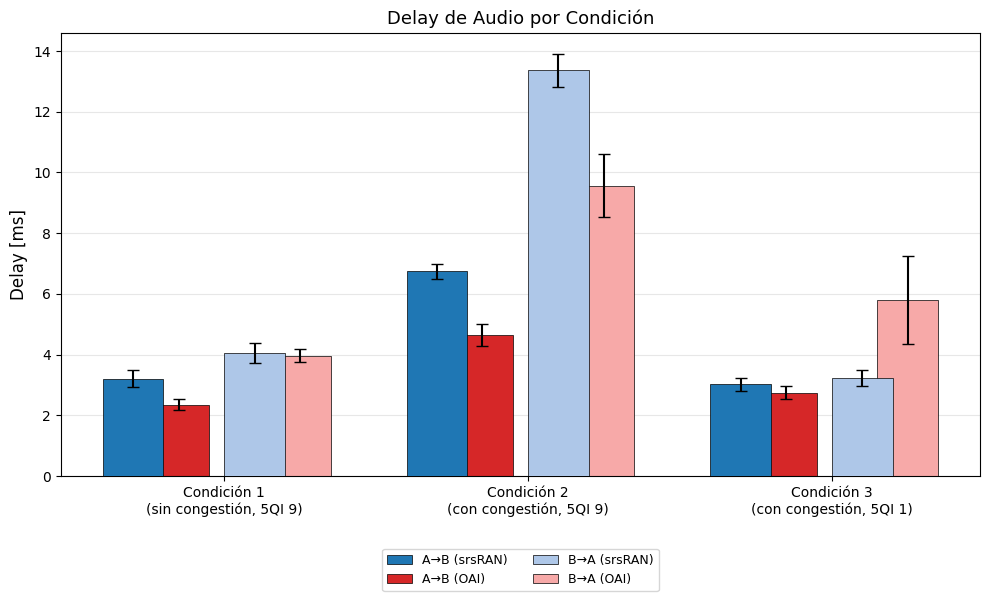

Guardado: graficos_overlap/delay_v.pdf


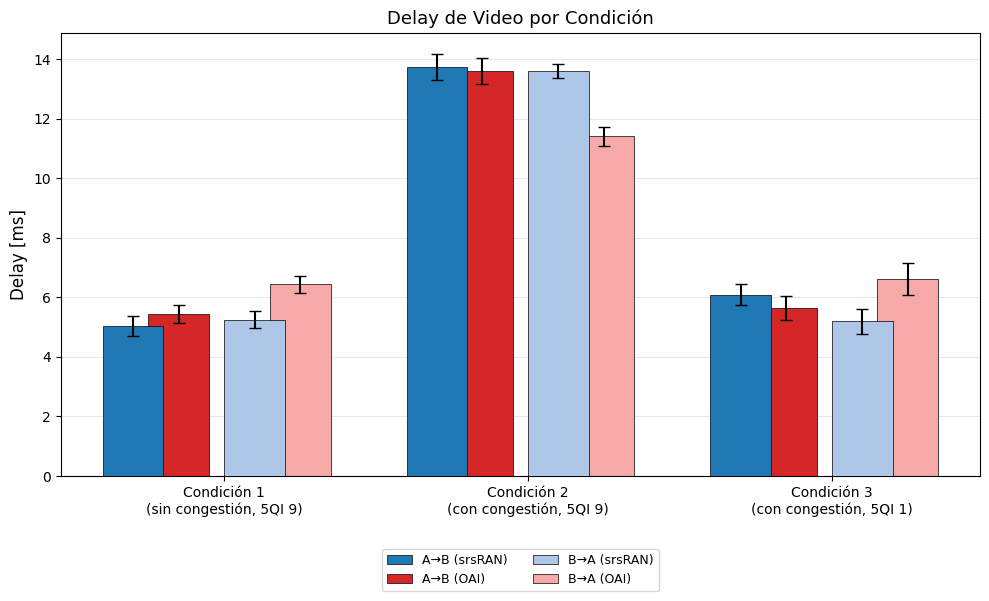

Guardado: graficos_overlap/jitter_s.pdf


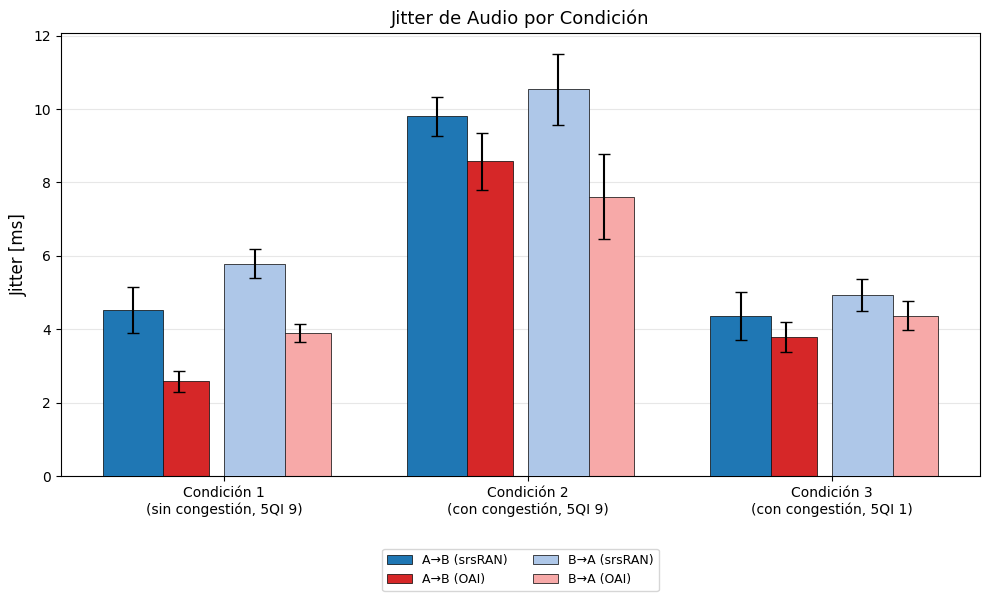

Guardado: graficos_overlap/jitter_v.pdf


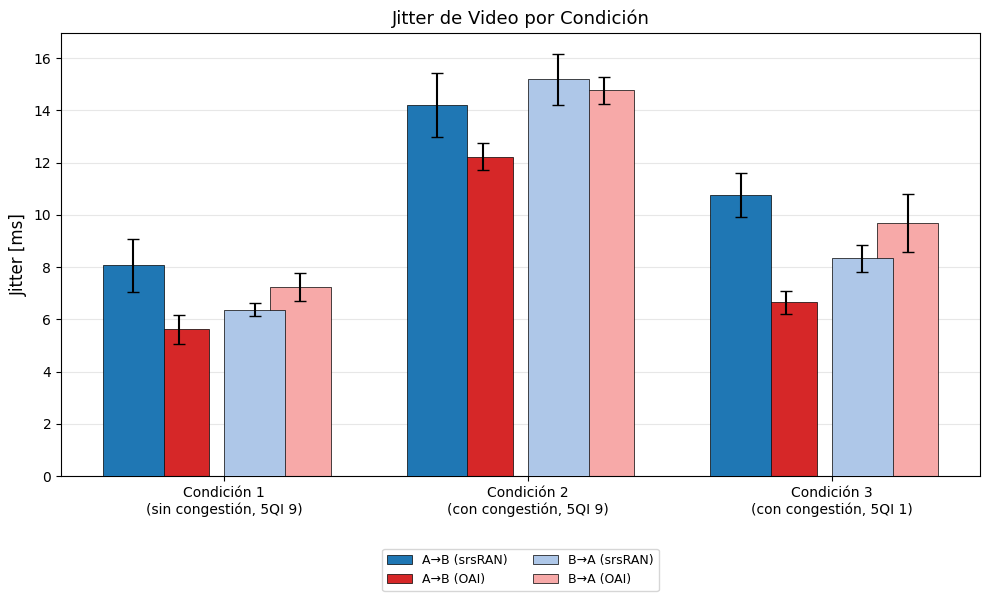

Guardado: graficos_overlap/loss_s.pdf


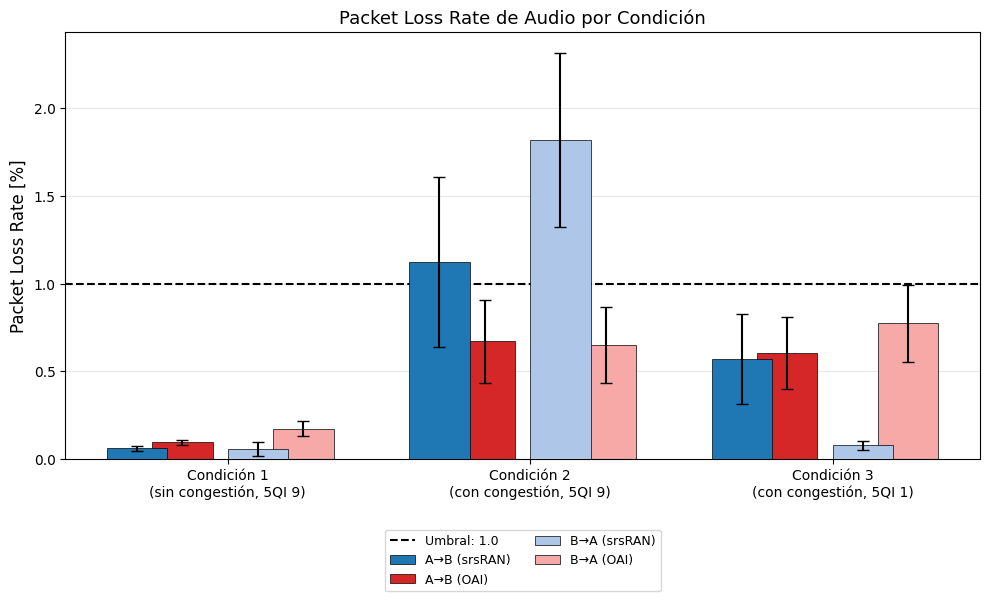

Guardado: graficos_overlap/loss_v.pdf


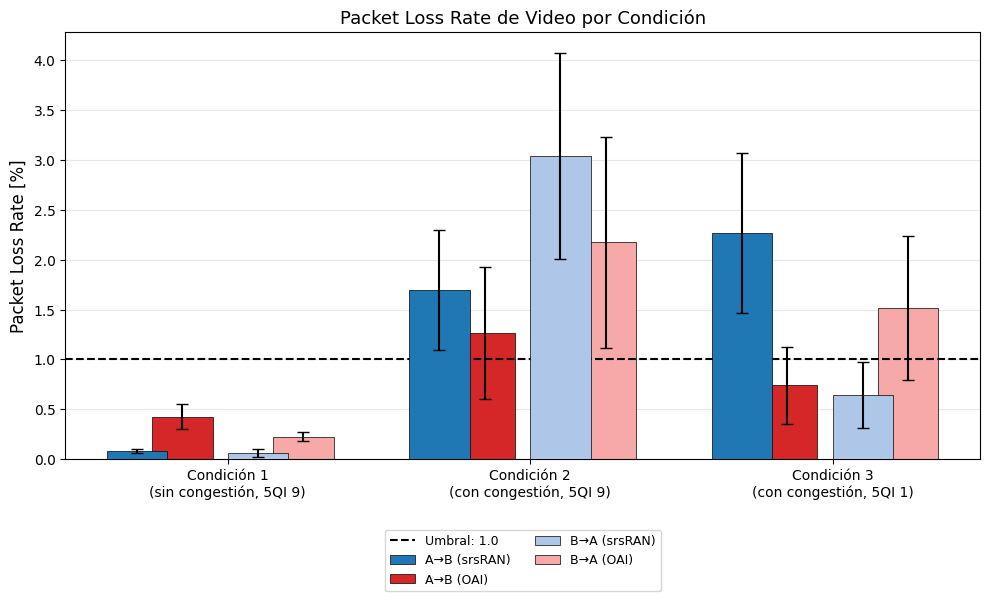

Guardado: graficos_overlap/sq.pdf


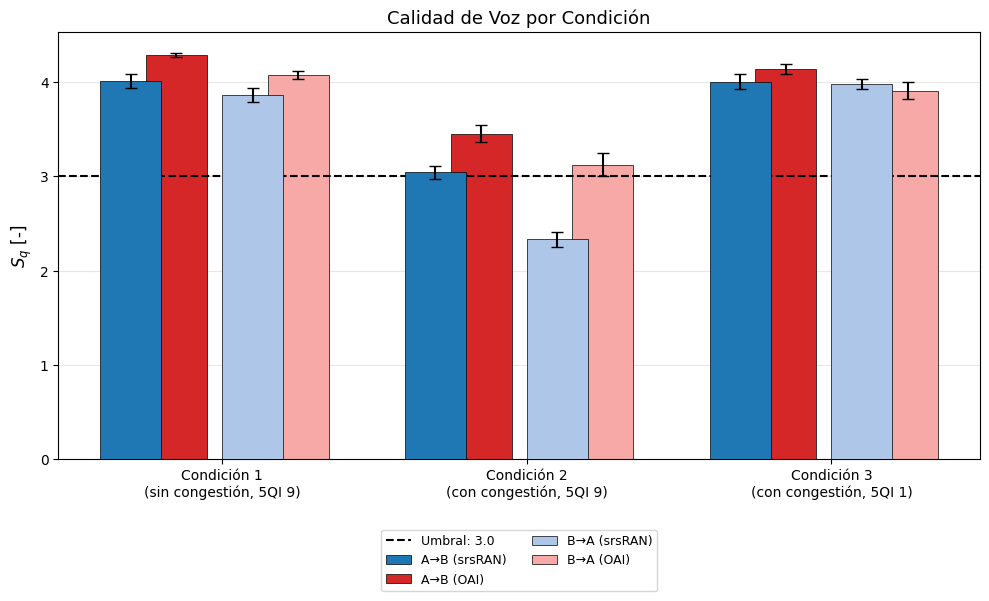

Guardado: graficos_overlap/vq.pdf


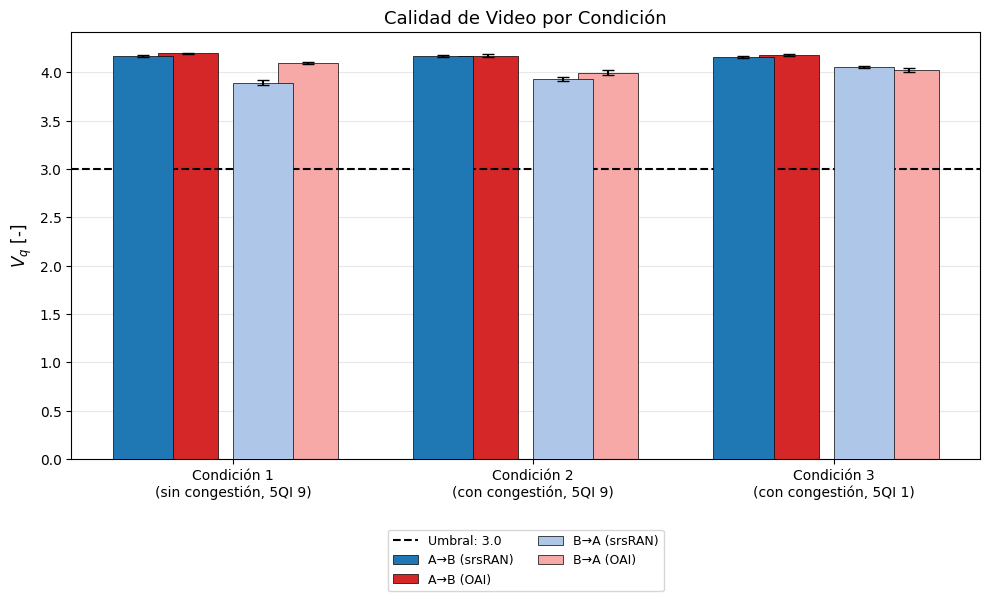

Guardado: graficos_overlap/mmq.pdf


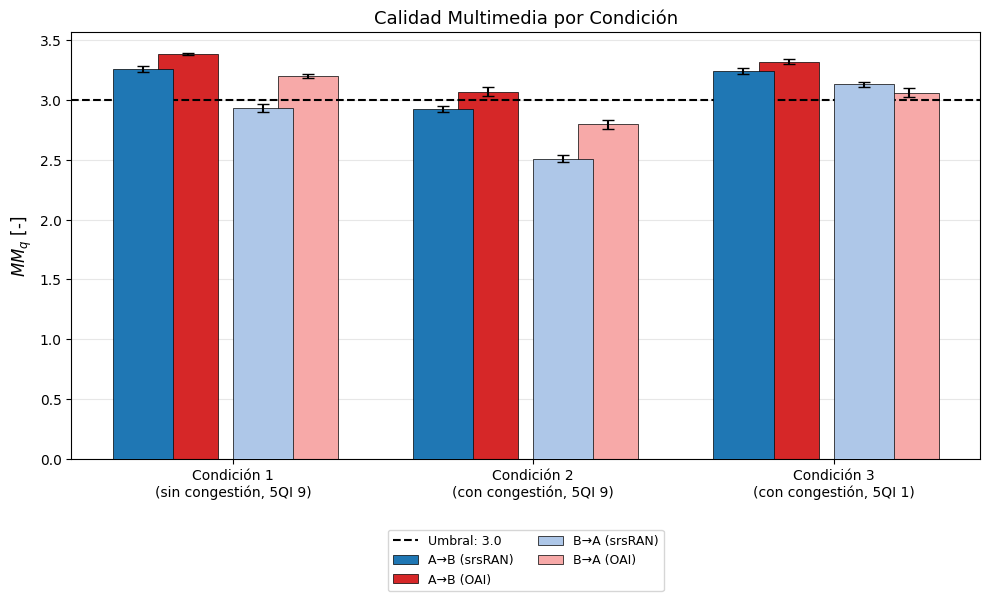

KeyError: 'bitrate_s_ab'

In [ ]:
cond_results = load_cond_results('cond_results.json')

plot_all_overlapped(cond_results, output_dir='graficos_overlap')

## 7. Boxplots (session-to-session consistency)

### 7.1 Boxplot functions

Unlike the bar charts, the boxplots re-read the raw CSV files so that the full distribution of the 21 iterations is visible (median, interquartile range, skew and outliers). They are used to check how consistent the sessions are within each condition.

In [ ]:
def plot_boxplots_by_condition(metric_key, ylabel, title,
                                threshold=None, save_path=None,
                                scenes_range=range(1, 19),
                                directions=['AB', 'BA']):
    """
    Genera boxplots por condición (3 grupos x 4 cajas) releyendo los CSVs.
    Misma estructura que plot_metric_overlapped pero con boxplots.

    Condiciones:
        1: srsRAN sin congestión  (E1-E3)  vs OAI sin congestión  (E10-E12)
        2: srsRAN con congestión 5QI9 (E4-E6) vs OAI (E13-E15)
        3: srsRAN con congestión 5QI1 (E7-E9) vs OAI (E16-E18)

    metric_key: 'delay_s', 'delay_v', 'jitter_s', 'jitter_v',
                'loss_s', 'loss_v', 'bitrate_s', 'bitrate_v',
                'sq', 'vq', 'mmq'
    """

    # Mapeo de metric_key a columna CSV y tipo de medio
    metric_map = {
        'delay_s':   ('audio', 'delay_network_ms'),
        'delay_v':   ('video', 'delay_network_ms'),
        'jitter_s':  ('audio', 'jitter_network_ms'),
        'jitter_v':  ('video', 'jitter_network_ms'),
        'loss_s':    ('audio', 'packet_loss_%'),
        'loss_v':    ('video', 'packet_loss_%'),
        'bitrate_s': ('audio', 'bitrate_kbps'),
        'bitrate_v': ('video', 'bitrate_kbps'),
        'sq':        ('qoe',   'sq'),
        'vq':        ('qoe',   'vq'),
        'mmq':       ('qoe',   'mmq'),
    }

    is_qoe = metric_map[metric_key][0] == 'qoe'
    media_type, col = metric_map[metric_key]

    conditions = {
        1: {'srs': [1,2,3],   'oai': [10,11,12]},
        2: {'srs': [4,5,6],   'oai': [13,14,15]},
        3: {'srs': [7,8,9],   'oai': [16,17,18]},
    }
    cond_labels = ['Condición 1\n(sin congestión, 5QI 9)',
                   'Condición 2\n(con congestión, 5QI 9)',
                   'Condición 3\n(con congestión, 5QI 1)']

    def get_raw_data(scenes, direction):
        """Relee los CSVs de los escenarios indicados y devuelve array crudo."""
        data = []
        for scene in scenes:
            if is_qoe:
                # Para QoE hay que recalcular desde los CSVs
                audio = pd.read_csv(f"audio_{direction}_scene{scene}.csv", delimiter=';')
                video = pd.read_csv(f"video_{direction}_scene{scene}.csv", delimiter=';')
                for N in range(21):
                    row_a = audio.iloc[N]
                    row_v = video.iloc[N]
                    speech_q = SpeechQuality(SCONSTANTS,
                                             row_a['packet_loss_%'],
                                             row_a['bitrate_kbps'],
                                             row_a['delay_network_ms'],
                                             row_a['jitter_network_ms']).get_value()
                    video_q  = VideoQuality(row_v['packet_loss_%'],
                                            row_v['bitrate_kbps'],
                                            row_v['delay_network_ms'],
                                            row_v['jitter_network_ms']).get_value()
                    mm_q     = MMQuality(row_a['delay_network_ms'],
                                         row_v['delay_network_ms'],
                                         speech_q, video_q,
                                         row_a['jitter_network_ms'],
                                         row_v['jitter_network_ms']).get_value()
                    if metric_key == 'sq':
                        data.append(speech_q)
                    elif metric_key == 'vq':
                        data.append(video_q)
                    else:
                        data.append(mm_q)
            else:
                df = pd.read_csv(f"{media_type}_{direction}_scene{scene}.csv", delimiter=';')
                data.extend(df[col].tolist())
        return data

    # Recopilar datos por condición y flujo
    raw = {}
    for cond, groups in conditions.items():
        raw[cond] = {
            'srs_ab': get_raw_data(groups['srs'], 'AB'),
            'srs_ba': get_raw_data(groups['srs'], 'BA'),
            'oai_ab': get_raw_data(groups['oai'], 'AB'),
            'oai_ba': get_raw_data(groups['oai'], 'BA'),
        }

    # Layout: 3 grupos, 4 cajas por grupo
    n      = 3
    gap    = 0.6   # separación entre grupos
    bwidth = 0.15  # ancho de cada caja
    offsets = [-1.5, -0.5, 0.5, 1.5]

    color_srs_ab = colors[0]
    color_oai_ab = colors[1]
    color_srs_ba = colors[2]
    color_oai_ba = colors[3]
    box_colors   = [color_srs_ab, color_oai_ab, color_srs_ba, color_oai_ba]
    box_labels   = ['A→B (srsRAN)', 'A→B (OAI)', 'B→A (srsRAN)', 'B→A (OAI)']
    box_keys     = ['srs_ab', 'oai_ab', 'srs_ba', 'oai_ba']

    fig, ax = plt.subplots(figsize=(11, 6))

    x_ticks = []
    for ci, cond in enumerate([1, 2, 3]):
        x_center = ci * (4 * bwidth + gap)
        x_ticks.append(x_center)
        for bi, (key, color, label) in enumerate(zip(box_keys, box_colors, box_labels)):
            x_pos = x_center + offsets[bi] * bwidth
            data  = raw[cond][key]

            bp = ax.boxplot(data,
                            positions=[x_pos],
                            widths=bwidth * 0.85,
                            patch_artist=True,
                            showmeans=True,
                            meanline=False,
                            meanprops=dict(marker='D', markerfacecolor='white',
                                           markeredgecolor='black', markersize=4),
                            medianprops=dict(color='red', linewidth=1),
                            boxprops=dict(facecolor=color, alpha=0.8),
                            whiskerprops=dict(color='black'),
                            capprops=dict(color='black'),
                            flierprops=dict(marker='o', markersize=2,
                                            markerfacecolor=color, alpha=0.5),
                            showfliers=False,
                            )

            mean_val = np.mean(data)
            ax.text(x_pos, mean_val, f'{mean_val:.2f}',
                    ha='center', va='bottom', fontsize=10,
                    color='black', fontweight='bold')
            # Etiqueta solo en primera condición para leyenda
            if ci == 0:
                bp['boxes'][0].set_label(label)

    if threshold is not None:
        ax.axhline(y=threshold, color='black', linestyle='--',
                   linewidth=1.5, label=f'Threshold: {threshold}')

    ax.set_xticks(x_ticks)
    ax.set_xticklabels(cond_labels, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
    plt.tight_layout(rect=[0, 0.1, 1, 1])
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"Saved: {save_path}")

    plt.show()
    return fig, ax


def plot_all_boxplots(output_dir='.'):
    """Genera todos los boxplots por condición."""

    # metrics = [
    #     ('delay_s',   'Delay [ms]',      'Audio Delay by Condition',         None),
    #     ('delay_v',   'Delay [ms]',      'Video Delay by Condition',          None),
    #     ('jitter_s',  'Jitter [ms]',     'Audio Jitter by Condition',         None),
    #     ('jitter_v',  'Jitter [ms]',     'Video Jitter by Condition',         None),
    #     ('loss_s',    'Packet Loss [%]', 'Audio Packet Loss by Condition',    1.0),
    #     ('loss_v',    'Packet Loss [%]', 'Video Packet Loss by Condition',    1.0),

    #     ('sq',        '$S_q$ [-]',       'Speech Quality by Condition',       3.0),
    #     ('vq',        '$V_q$ [-]',       'Video Quality by Condition',        3.0),
    #     ('mmq',       '$MM_q$ [-]',      'Multimedia Quality by Condition',   3.0),
    # ]

    metrics = [
        # (metric_key,  ylabel,              title,                          threshold)
        ('delay_s',   'Delay [ms]',         'Delay de Audio por Condición',       None),
        ('delay_v',   'Delay [ms]',         'Delay de Video por Condición',       None),
        ('jitter_s',  'Jitter [ms]',        'Jitter de Audio por Condición',      None),
        ('jitter_v',  'Jitter [ms]',        'Jitter de Video por Condición',      None),
        ('bitrate_s', 'Bitrate [kb/s]',  'Bitrate de Audio por Condición',        None),
        ('bitrate_v', 'Bitrate [kb/s]',  'Bitrate de Video por Condición',        None),
        ('loss_s',    'Packet Loss Rate [%]',    'Packet Loss Rate de Audio por Condición', 1.0),
        ('loss_v',    'Packet Loss Rate [%]',    'Packet Loss Rate de Video por Condición', 1.0),
        ('sq',        '$S_q$ [-]',          'Calidad de Voz por Condición',       3.0),
        ('vq',        '$V_q$ [-]',          'Calidad de Video por Condición',     3.0),
        ('mmq',       '$MM_q$ [-]',         'Calidad Multimedia por Condición',   3.0),
      ]

    for metric_key, ylabel, title, threshold in metrics:
        save_path = f"{output_dir}/{metric_key}_boxplot.pdf"
        plot_boxplots_by_condition(
            metric_key, ylabel, title,
            threshold=threshold, save_path=save_path
        )

    import zipfile, os
    zip_path = f"{output_dir}/boxplots.zip"
    with zipfile.ZipFile(zip_path, 'w') as zipf:
        for f in os.listdir(output_dir):
            if f.endswith('_boxplot.pdf'):
                zipf.write(os.path.join(output_dir, f), f)
    print(f"✅ ZIP saved: {zip_path}")

### 7.2 Generate all boxplots

Creates one boxplot per metric and saves them in `graficos_boxplot/`, together with `boxplots.zip`.

Saved: graficos_boxplot/delay_s_boxplot.pdf


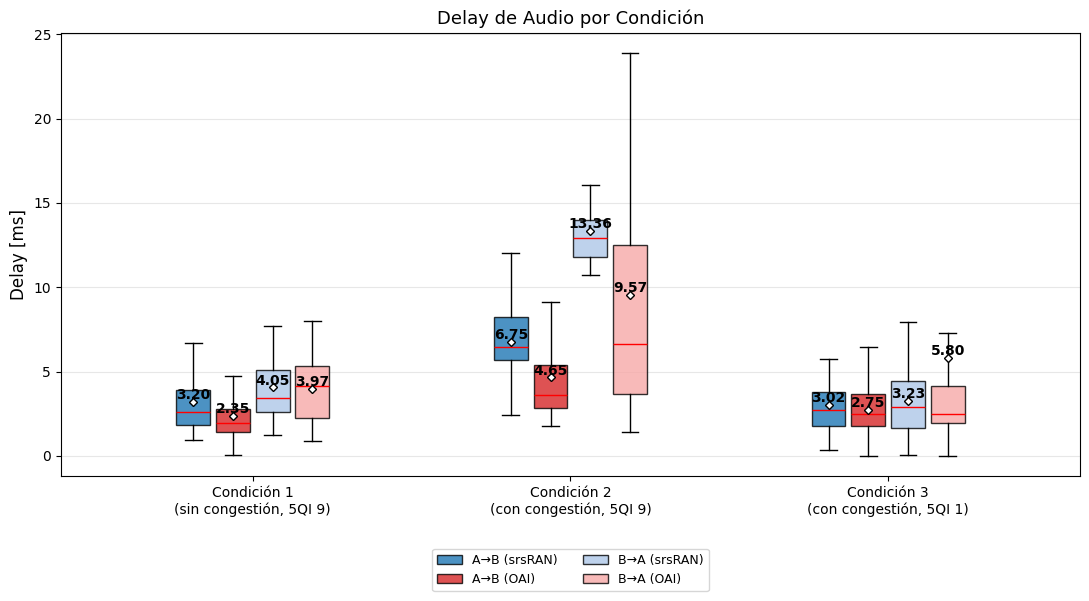

Saved: graficos_boxplot/delay_v_boxplot.pdf


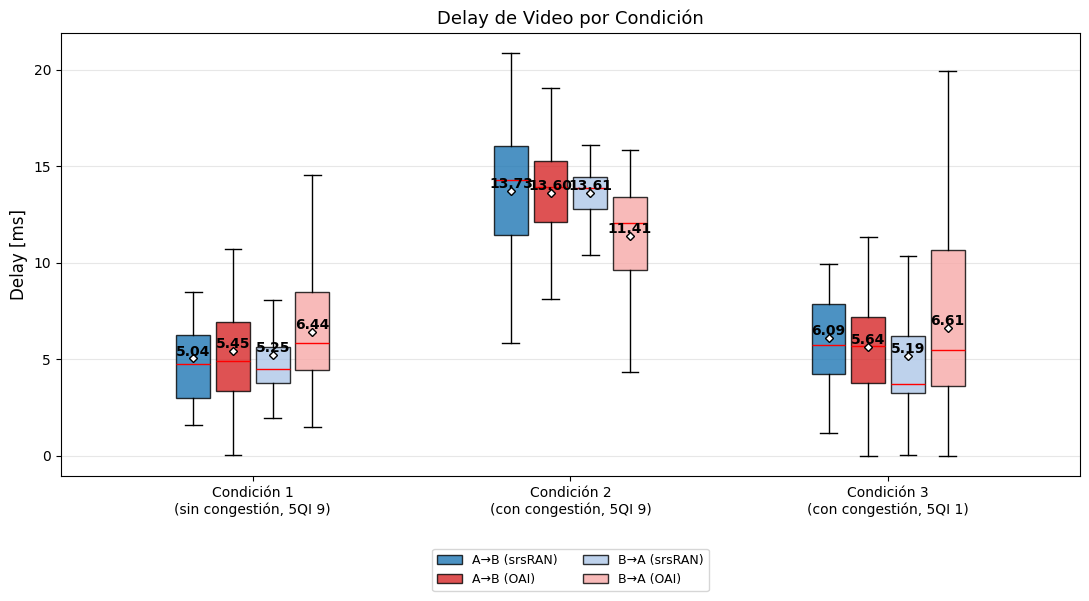

Saved: graficos_boxplot/jitter_s_boxplot.pdf


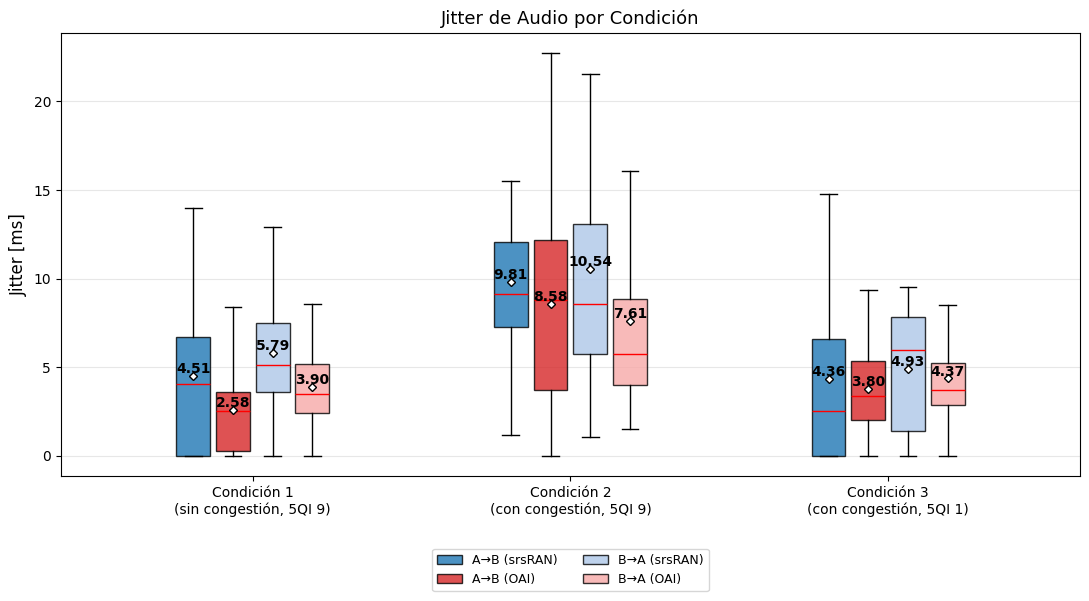

Saved: graficos_boxplot/jitter_v_boxplot.pdf


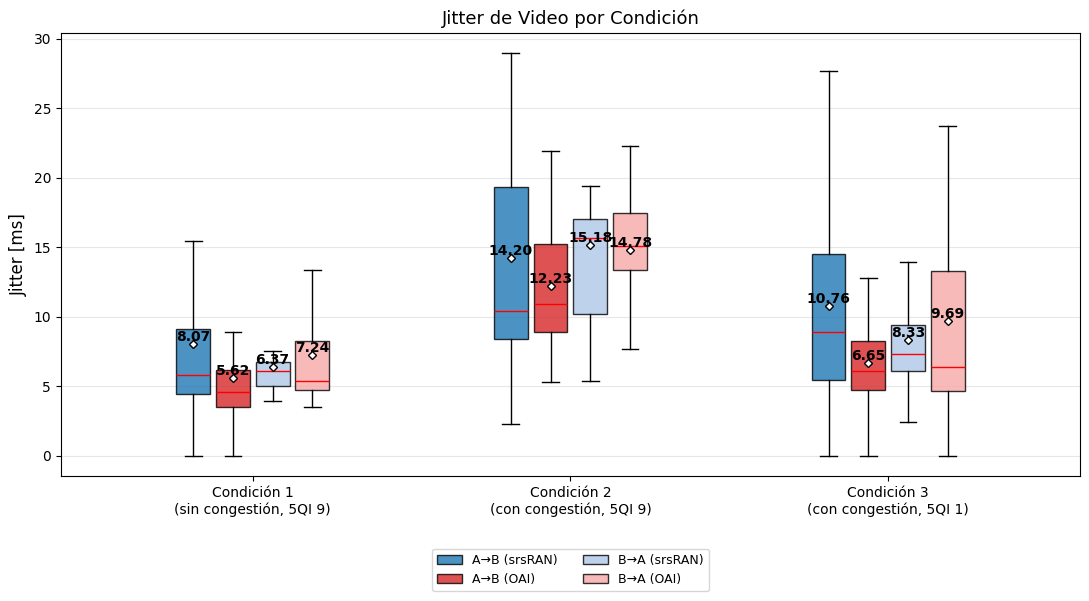

Saved: graficos_boxplot/bitrate_s_boxplot.pdf


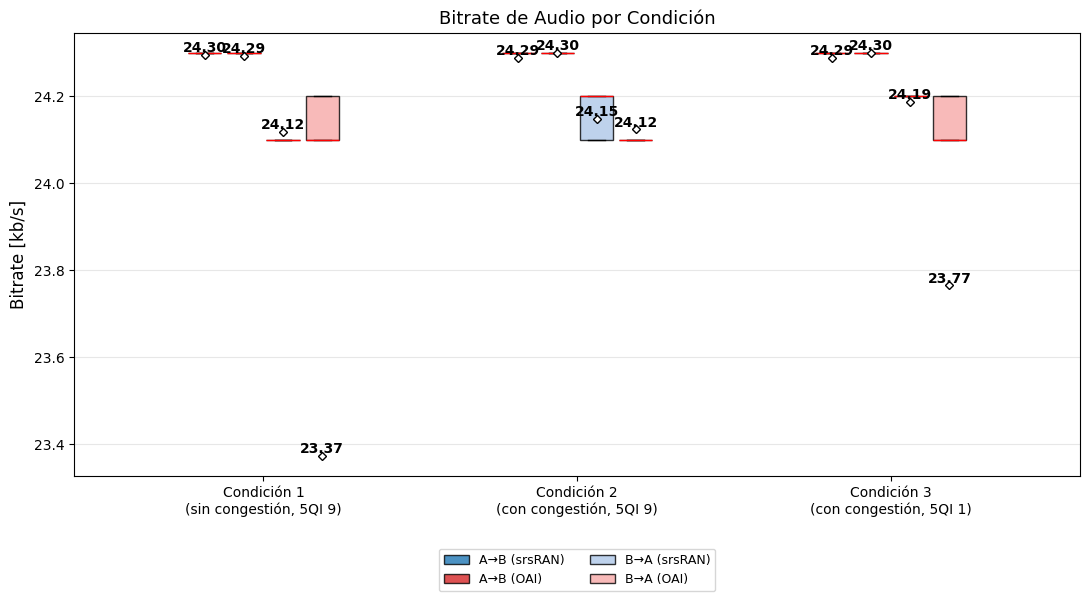

Saved: graficos_boxplot/bitrate_v_boxplot.pdf


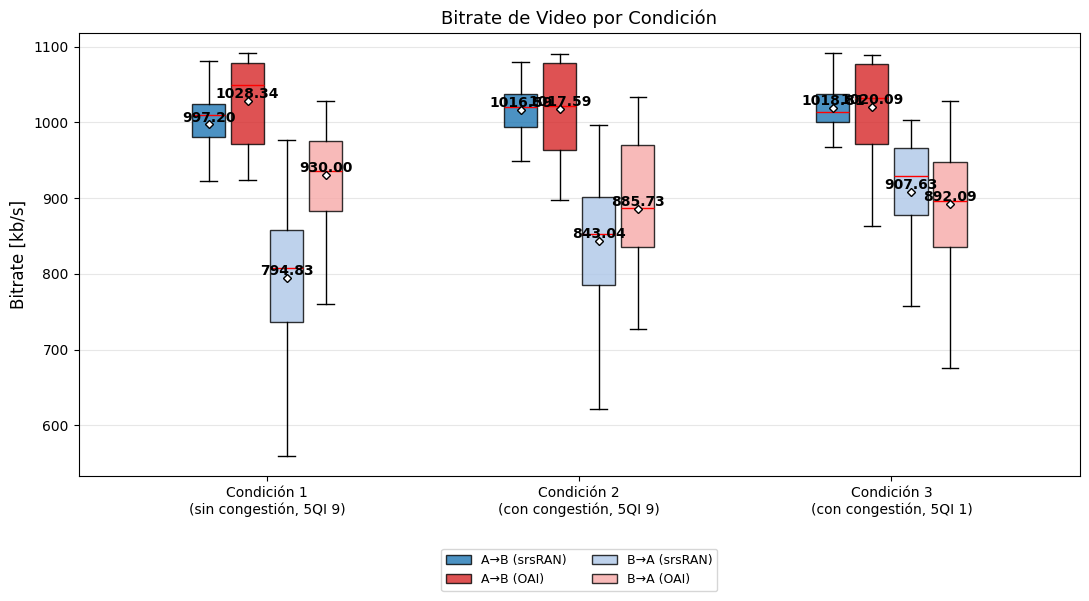

Saved: graficos_boxplot/loss_s_boxplot.pdf


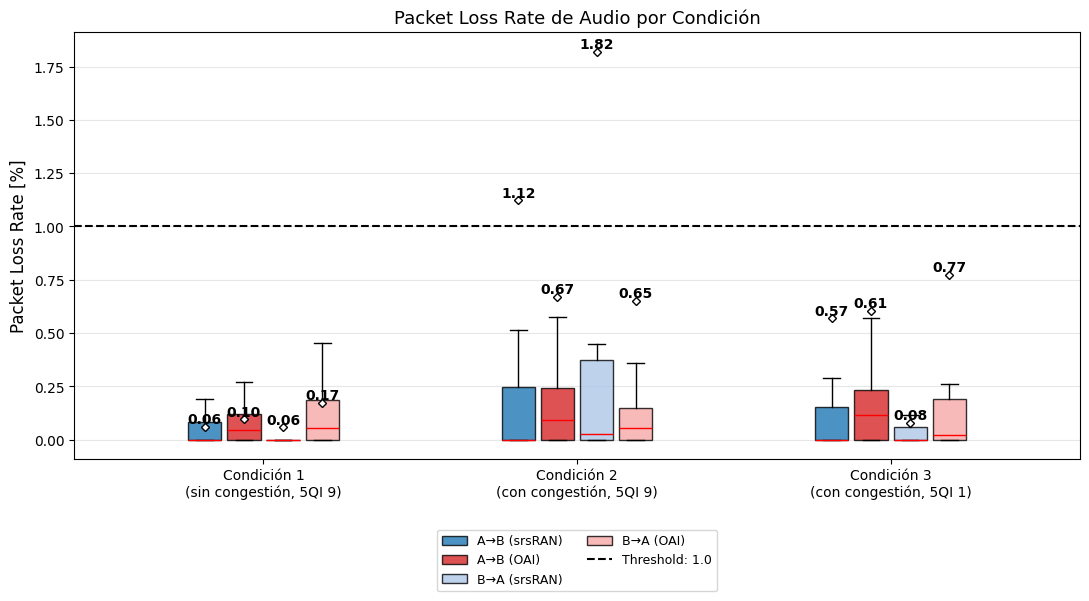

Saved: graficos_boxplot/loss_v_boxplot.pdf


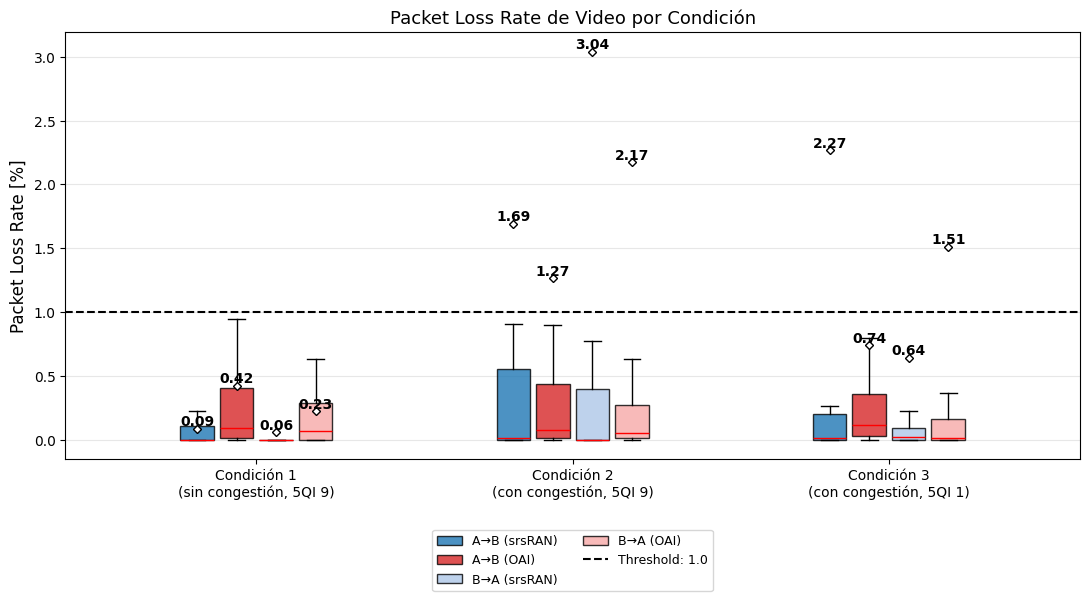

Saved: graficos_boxplot/sq_boxplot.pdf


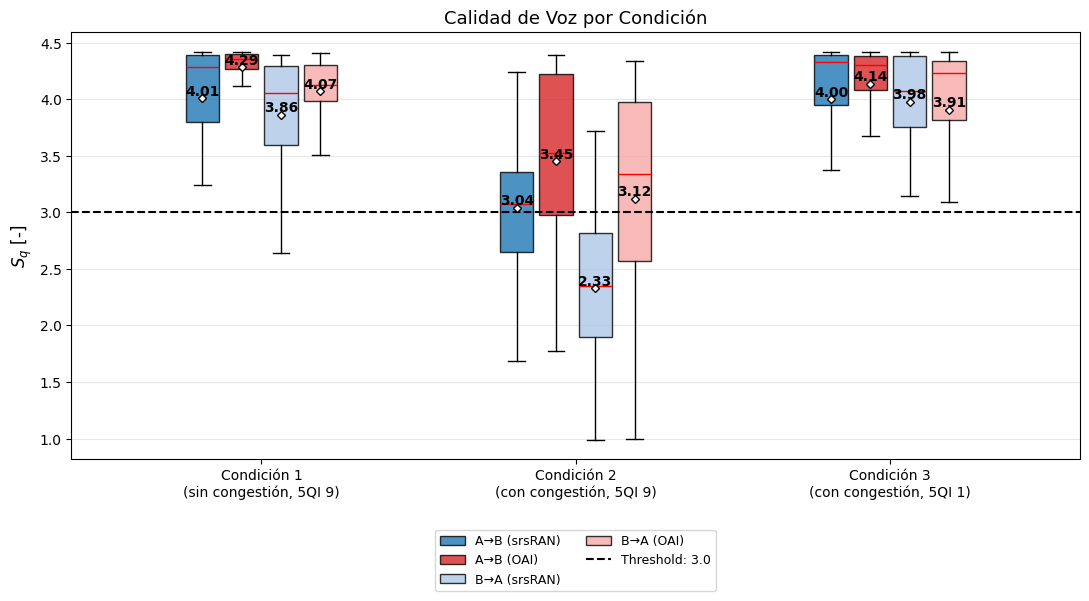

Saved: graficos_boxplot/vq_boxplot.pdf


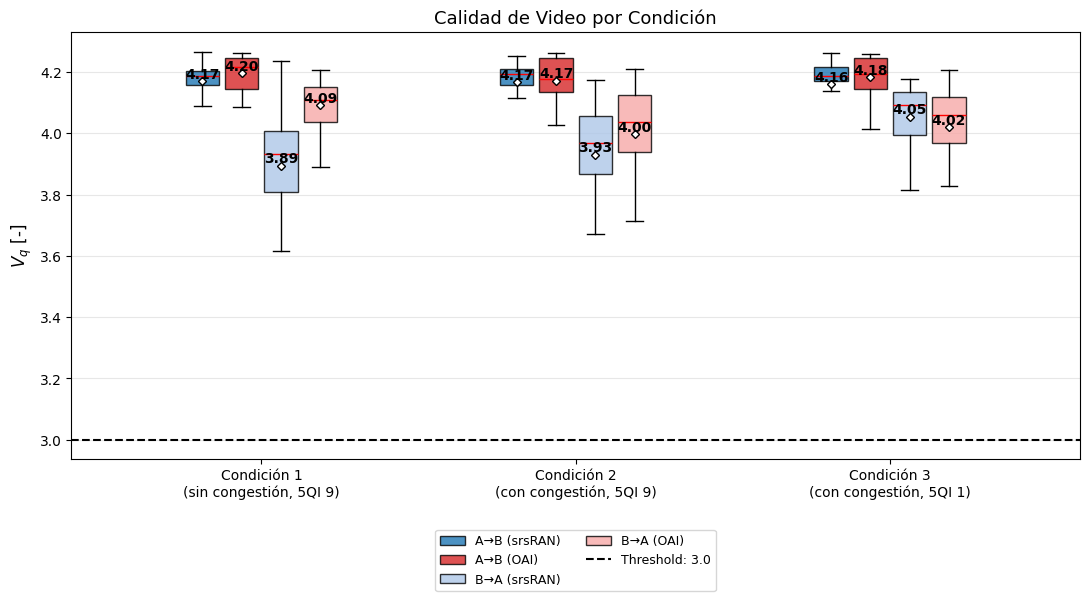

Saved: graficos_boxplot/mmq_boxplot.pdf


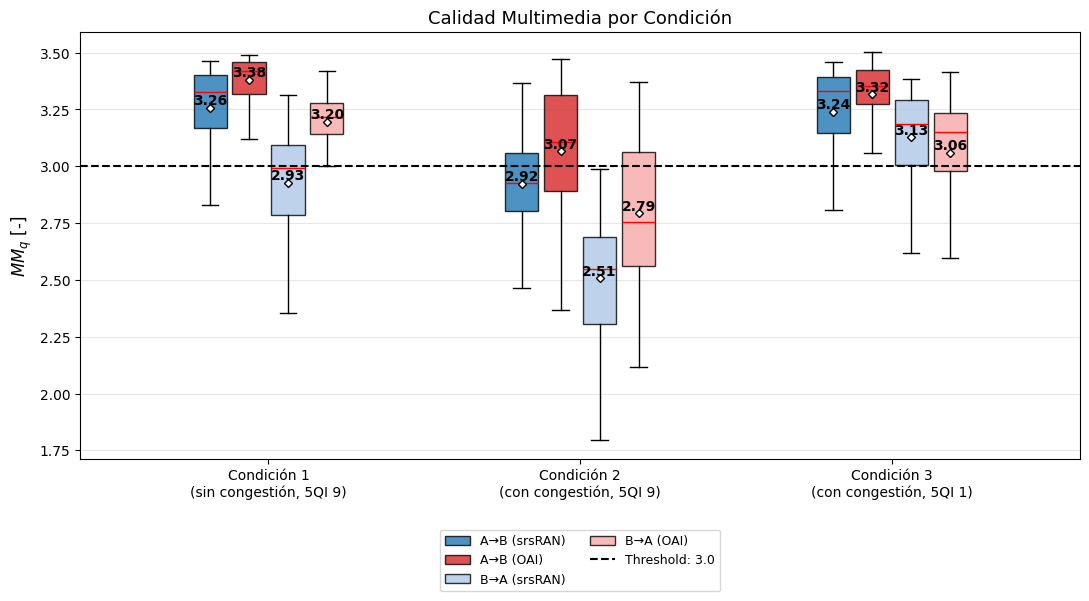

✅ ZIP saved: graficos_boxplot/boxplots.zip


In [ ]:
plot_all_boxplots(output_dir='graficos_boxplot')